# LightCyto — CRIC binary cell classification: fresh matched ablation

**A standalone notebook for [this dataset](https://www.kaggle.com/datasets/alexfordna/cric-dataset).** Train a new dataset-specific teacher and 12 students. No SIPaKMeD checkpoint, feature cache, split CSV or previous output is required. ImageNet pretrained initialization is used; “fresh” means fresh fine-tuning on this dataset, not random initialization.

| Arm | Custom attention | Dataset-specific KD | Loss |
|---|---|---|---|
| A — TinyViT + shared head | No | No | CE |
| B — TinyViT + shared head + KD | No | Yes | CE + 0.25 KD |
| C — TinyViT + custom attention | Yes | No | CE |
| D — Full global model | Yes | Yes | CE + 0.25 KD |

**Each arm:** seeds 42, 123, 2026; 45 epochs; same split, ImageNet pretraining, augmentation schedule and common initial tensors. **Teacher:** ConvNeXt-Tiny, 12 epochs, selected by validation and frozen. **Input:** 224×224; **classes:** 2.

This is your current **global TinyViT model**. PPO, crop fusion, RKD, TTA and ensembles are not active in these four ablations. KD here is additional dataset-specific distillation; the shared TinyViT pretrained weights already used ImageNet distillation.

Each dataset is trained and tested independently. These experiments assess the method on additional datasets, **not zero-shot external validation of one SIPaKMeD-trained checkpoint**. Accuracy/F1 are measured after running; no target accuracy is guaranteed.

## CRIC missing-image fix — verified against the full archive

The public **alexfordna/cric-dataset, version 2** archive contains **11,242 image files**, while `binary_labels.csv` has **11,534 rows**. **292 listed images are absent**, including `47.png`: 176 label-0 and 116 label-1 images. Available rows are 6,603 label-0 and 4,639 label-1, before exact-pixel deduplication.

The earlier loader stopped at the first missing file. This version audits the entire CSV first. Default `missing_image_policy='verified_release_only'` excludes **only** absences in the readable, verified v2 allow-list, and only when the CSV SHA-256 matches the inspected release. It never shifts labels, substitutes nearby numbered images, or accepts an unexpected missing image. Set the policy to `'error'` if you require all CSV-listed images; that requires obtaining the absent source files.

Every exclusion is saved in `missing_images.csv`. `csv_image_coverage.json` and `csv_image_coverage_by_class.csv` record counts before splitting. **Report this as evaluation on the available labelled subset**, with the exclusion counts; the 292 unavailable images are not tested. Training, ablation settings and the image-level grouping limitation remain as documented below.

The updated loader was also run against the actual downloaded archive: 4 repeated pixel-identical images were removed, leaving **11,238 unique images**. With the default split settings this produced **7,866 train / 1,686 validation / 1,686 test** images. These are data-audit counts, not model accuracy results. Your runtime audit remains authoritative if the input changes.

The screenshot error occurs before training. Import this updated notebook, retain the CRIC dataset attachment, and **Restart Session → Run All**. Leave `dataset_root=''`; it discovers `/kaggle/input/datasets/alexfordna/cric-dataset` and other supported mounts. An old experiment with completed training must use a separate output folder because the data-coverage contract has changed.

## Dataset-specific scope — read before reporting

The complete public archive and its `binary_labels.csv` were inspected: **11,534 rows**, columns **`path,label`**, with 6,779 rows labelled `0` and 4,755 labelled `1`. These are raw CSV counts before any duplicate removal. This notebook matches paths to the nested `CRIC_cell_images` directory and uses **two output classes**, `Class_0` and `Class_1`.

**The meaning of 0/1 is not guessed.** Do not call either class “normal” or “abnormal” without confirming the uploader's mapping. The parent CRIC resource has richer multiclass/source annotations, but they cannot be assumed to match these renamed numeric crop files.

**No source-image or patient ID is present in this CSV.** By default this is an **image-level exploratory split** after exact-pixel deduplication. Related crops may still cross splits. It is not patient-independent or source-independent evidence. Numeric filenames such as `1000.png` are not treated as patient IDs.

If you have verified crop-to-source/slide/patient mapping, set `group_csv` to a CSV with `path,group_id`, covering every labelled image, **before training**. The same code will then keep those groups disjoint. Adding groups after a run requires a new output folder and a new experiment; it does not repair the previous evaluation retroactively.

## Kaggle setup

1. Create a new Kaggle notebook and import this `.ipynb`.
2. Attach **only the relevant image dataset**: `alexfordna/cric-dataset`. Do not attach a reports archive as an image dataset.
3. Enable **GPU** and **Internet** for package and pretrained-weight downloads. All runs use `cuda:0`.
4. Leave `dataset_root=''` for automatic discovery under `/kaggle/input`, including the newer nested mount layout. Then **Run All**. If multiple copies are attached, set the exact root path in Configuration.

No compressed/encoded Python payloads or separate helper uploads are used. Output: `/kaggle/working/lightcyto_cric_ablation`. There are **12 student training jobs**, so this may require multiple GPU sessions. Epoch logs estimate remaining time for the current job; wall time depends on hardware and dataset size.

In [1]:
import importlib.metadata, importlib.util, subprocess, sys
PINNED_TIMM = '1.0.22'
PINNED_FVCORE = '0.1.5.post20221221'
for package, version, no_deps in [('timm', PINNED_TIMM, True), ('fvcore', PINNED_FVCORE, False)]:
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        if package in sys.modules:
            raise RuntimeError('Restart the kernel before changing an imported package: '+package)
        command = [sys.executable, '-m', 'pip', 'install', '--quiet']
        if no_deps:
            command.append('--no-deps')
        subprocess.check_call(command+[package+'=='+version])
missing = [x for x in ('huggingface_hub','safetensors') if importlib.util.find_spec(x) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
# Keep Kaggle's installed CUDA-compatible torch/torchvision builds.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 76.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 7.6 MB/s eta 0:00:00


## Imports

Dependencies are pinned where appropriate; retain Kaggle’s matching CUDA torch/torchvision builds.

In [2]:
from __future__ import annotations
import os, sys, re, io, json, math, time, copy, random, hashlib, shutil, zipfile, gc, inspect, platform, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
from collections import defaultdict
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageEnhance
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import timm
import sklearn
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix
from fvcore.nn import FlopCountAnalysis

## Configuration

Defaults run all four arms × three seeds and then final testing. `dataset_root` is the image-data folder, not an old output. Optional `group_csv` has columns `path,group_id`; it must cover all labelled images.

`resume_source` is the **full output of this exact notebook**, containing `ablation_contract.json`, `teacher/`, `initialization/` and all arm folders with `.pt` files. Keep it blank on a fresh run. Scientific settings cannot change while resuming.

`session_hours=10` pauses between epochs/stages; an epoch already running may finish after this boundary. `run_final_test=True` evaluates all 12 locked checkpoints after training. Do not repeatedly tune this model using test results.

In [3]:
DATASET_KIND = 'cric'
DATASET_SLUG = 'alexfordna/cric-dataset'
CLASSES = ('Class_0', 'Class_1')
OUTPUT_DEFAULT = '/kaggle/working/lightcyto_cric_ablation'

@dataclass
class Config:
    dataset_root: str = ''  # Blank finds this dataset under /kaggle/input, including nested mounts.
    missing_image_policy: str = 'verified_release_only'  # Only known public v2 absences; 'error' forbids all exclusions.
    labels_csv: str = ''    # CRIC only: blank locates binary_labels.csv automatically.
    group_csv: str = ''     # Optional verified metadata CSV: path,group_id; cover ALL images.
    output_root: str = OUTPUT_DEFAULT
    resume_source: str = '' # THIS notebook's FULL saved output, not its reports-only ZIP.
    split_seed: int = 3407
    val_fraction: float = .15
    test_fraction: float = .15
    seeds: tuple = (42,123,2026)
    teacher_seed: int = 7001
    image_size: int = 224
    feature_dim: int = 192
    attention_heads: int = 4
    batch_size: int = 16
    teacher_batch_size: int = 8
    num_workers: int = 0
    teacher_epochs: int = 12
    student_epochs: int = 45
    teacher_lr: float = 1e-4
    student_lr: float = 3e-4
    weight_decay: float = 1e-4
    label_smoothing: float = .05
    kd_weight: float = .25
    kd_temperature: float = 2.
    pretrained: bool = True
    amp: bool = True
    allow_cpu: bool = False
    session_hours: float = 10.
    run_final_test: bool = True
    bootstrap_replicates: int = 2000
    bootstrap_seed: int = 91723
    benchmark_images: int = 64
    benchmark_repeats: int = 3
    benchmark_warmup: int = 20

CFG = Config()
STUDENT_NAME = 'tiny_vit_5m_224.dist_in22k_ft_in1k'
VERSION = 'lightcyto-cric-verified-coverage-v2'
ARMS = {
    'A_PLAIN': {'attention':False, 'kd':False, 'label':'TinyViT + shared head'},
    'B_KD': {'attention':False, 'kd':True, 'label':'TinyViT + shared head + KD'},
    'C_ATTENTION': {'attention':True, 'kd':False, 'label':'TinyViT + custom attention'},
    'D_FULL': {'attention':True, 'kd':True, 'label':'TinyViT + custom attention + KD'},
}
PRIMARY_ARM = 'D_FULL'
MEAN = torch.tensor([.485,.456,.406]).view(1,3,1,1)
STD = torch.tensor([.229,.224,.225]).view(1,3,1,1)

## Utilities and resume

Atomic checkpoint writes and exact code/data/runtime contract checks prevent silent mixing of incompatible jobs. Resume is at completed epoch boundaries.

In [4]:
class SessionPause(RuntimeError): pass

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def json_value(x):
    if isinstance(x, dict): return {str(k):json_value(v) for k,v in x.items()}
    if isinstance(x, (tuple,list)): return [json_value(v) for v in x]
    if isinstance(x, (np.integer,np.floating)): return x.item()
    if isinstance(x, Path): return str(x)
    if isinstance(x, torch.Tensor): return x.detach().cpu().tolist()
    return x

def save_json(x, path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(json_value(x),indent=2,allow_nan=False)); os.replace(tmp,path)

def read_json(path): return json.loads(Path(path).read_text())

def object_hash(x): return hashlib.sha256(json.dumps(json_value(x),sort_keys=True).encode()).hexdigest()

def file_hash(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def save_pt(x,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp');torch.save(x,tmp);os.replace(tmp,path)

def load_pt(path): return torch.load(path,map_location='cpu',weights_only=True)

def cpu_state(model): return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}

def clear_bias_cache(model):
    for m in model.modules():
        if hasattr(m,'attention_bias_cache'): m.attention_bias_cache.clear()

def install_state(model,state):
    model.load_state_dict(state,strict=True);clear_bias_cache(model)

def budget(ctx):
    if time.monotonic() >= ctx['deadline']: raise SessionPause('Session budget reached; resume this full output.')

def metric_values(y,logits,crops=None):
    y=np.asarray(y,dtype=int);logits=np.asarray(logits,dtype=np.float64)
    assert len(y)>0 and logits.shape==(len(y),len(CLASSES)) and np.isfinite(logits).all()
    p=np.exp(logits-logits.max(1,keepdims=True));p/=p.sum(1,keepdims=True);pred=p.argmax(1)
    result={'n':len(y),'correct':int((y==pred).sum()),'accuracy':float(accuracy_score(y,pred)),
            'macro_f1':float(f1_score(y,pred,labels=list(range(len(CLASSES))),average='macro',zero_division=0)),
            'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'ce':float(-np.log(p[np.arange(len(y)),y].clip(1e-12)).mean())}
    if crops is not None: result['mean_crops']=float(np.mean(crops))
    return result

def quality(m): return (m['macro_f1'],m['accuracy'],-m.get('mean_crops',0.),-m['ce'])

def freeze(model):
    model.eval()
    for p in model.parameters():p.requires_grad_(False)
    return model

def implementation_hash():
    # Functions/methods are source-resolvable in IPython; whole interactive classes may not be.
    definitions={}
    for name,obj in globals().copy().items():
        if name=='Config':continue  # Scientific config values are hashed separately.
        if getattr(obj,'__module__',None)!=__name__:continue
        try:
            if inspect.isfunction(obj):definitions[name]=inspect.getsource(obj).strip()
            elif inspect.isclass(obj):
                methods={}
                for key,value in vars(obj).items():
                    if isinstance(value,(staticmethod,classmethod)):value=value.__func__
                    if inspect.isfunction(value):methods[key]=inspect.getsource(value).strip()
                definitions[name]={'bases':[base.__name__ for base in obj.__bases__],'methods':methods}
        except (OSError,TypeError) as e:
            raise RuntimeError('Run the visible notebook definition cells normally before prepare().') from e
    return object_hash(definitions)

def restore_ablation():
    root = Path(CFG.output_root).expanduser()
    if CFG.resume_source:
        source = Path(CFG.resume_source).expanduser()
        if not (source/'ablation_contract.json').is_file():
            raise FileNotFoundError('resume_source must be the FULL output of THIS ablation notebook, '
                                    'containing ablation_contract.json and model .pt files.')
        if next(source.rglob('*.pt'), None) is None:
            raise FileNotFoundError('This folder contains reports but no model .pt files. '
                                    'Attach the FULL ablation output to resume; the reports ZIP cannot resume training.')
        if source.resolve() != root.resolve():
            if root.exists() and any(root.iterdir()):
                print('Existing working ablation output takes priority; its contract will be checked.')
            else:
                shutil.copytree(source, root, dirs_exist_ok=True)
    root.mkdir(parents=True, exist_ok=True)
    return root

def runtime_identity():
    return {'torch': str(torch.__version__), 'torchvision': str(torchvision.__version__),
            'timm': timm.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
            'sklearn': sklearn.__version__, 'python': platform.python_version()}

## Dataset discovery and audited splitting

Data discovery uses the observed folder/CSV structure. Known CRIC v2 missing images are audited and excluded under the verified policy. Unexpected missing images, ambiguous basenames, conflicting duplicate labels and incomplete group metadata raise actionable errors. The split seed is shared by every arm and training seed. Class balancing of the split uses labels only, never model performance.

The manifest is regenerated deterministically and checked against the saved contract on resume. File paths may move without changing identity. Test pixels are decoded only for integrity checks here, and test labels are used only for partition stratification, not learning or checkpoint selection.

In [5]:
# Verified against the complete public Kaggle v2 archive, not a partial file listing.
# The readable allow-list is DATA (filenames), not an encoded executable payload.
CRIC_RELEASE_REFERENCE = {'version': 2, 'labels_sha256': 'a819214d5285fd3082c225ab59ca913e87050fc48fca46dcec6d51cb57ae5d67', 'archive_sha256': '91c52445d85bfb32cdbca3757fc01eb33b5cd7e15914993124d8ce2fde0fd6c6', 'image_count': 11242, 'csv_rows': 11534, 'retained_by_label': {'0': 6603, '1': 4639}}
CRIC_KNOWN_MISSING = frozenset((
    '47.png', '120.png', '124.png', '131.png', '150.png', '234.png', '242.png', '397.png', '412.png', '427.png',
    '440.png', '493.png', '521.png', '526.png', '529.png', '540.png', '548.png', '672.png', '714.png', '737.png',
    '792.png', '822.png', '841.png', '900.png', '914.png', '947.png', '975.png', '1008.png', '1013.png', '1014.png',
    '1073.png', '1168.png', '1215.png', '1224.png', '1225.png', '1228.png', '1236.png', '1280.png', '1290.png', '1302.png',
    '1323.png', '1345.png', '1489.png', '1590.png', '1624.png', '1633.png', '1812.png', '1816.png', '1843.png', '1902.png',
    '1936.png', '1937.png', '1949.png', '1952.png', '1974.png', '1999.png', '2032.png', '2121.png', '2180.png', '2199.png',
    '2226.png', '2245.png', '2282.png', '2354.png', '2372.png', '2380.png', '2383.png', '2434.png', '2446.png', '2480.png',
    '2499.png', '2513.png', '2633.png', '2693.png', '2725.png', '2734.png', '2749.png', '2755.png', '2800.png', '2837.png',
    '2882.png', '2891.png', '2935.png', '2946.png', '2964.png', '2981.png', '2997.png', '3025.png', '3049.png', '3093.png',
    '3094.png', '3104.png', '3143.png', '3150.png', '3165.png', '3193.png', '3259.png', '3293.png', '3348.png', '3355.png',
    '3426.png', '3445.png', '3484.png', '3509.png', '3542.png', '3579.png', '3763.png', '3777.png', '3811.png', '3929.png',
    '3931.png', '4007.png', '4053.png', '4085.png', '4096.png', '4103.png', '4194.png', '4234.png', '4247.png', '4275.png',
    '4305.png', '4316.png', '4350.png', '4420.png', '4538.png', '4577.png', '4617.png', '4653.png', '4685.png', '4704.png',
    '4811.png', '4816.png', '4827.png', '4861.png', '4898.png', '4936.png', '4980.png', '4981.png', '5014.png', '5189.png',
    '5194.png', '5205.png', '5213.png', '5271.png', '5279.png', '5299.png', '5315.png', '5348.png', '5385.png', '5396.png',
    '5487.png', '5499.png', '5535.png', '5609.png', '5627.png', '5638.png', '5692.png', '5781.png', '5797.png', '6008.png',
    '6072.png', '6144.png', '6194.png', '6225.png', '6236.png', '6265.png', '6315.png', '6333.png', '6358.png', '6439.png',
    '6467.png', '6476.png', '6507.png', '6513.png', '6606.png', '6608.png', '6617.png', '6643.png', '6660.png', '6662.png',
    '6694.png', '6811.png', '6850.png', '6871.png', '6902.png', '6903.png', '6915.png', '6934.png', '6940.png', '7068.png',
    '7145.png', '7152.png', '7254.png', '7292.png', '7359.png', '7412.png', '7476.png', '7491.png', '7504.png', '7512.png',
    '7525.png', '7579.png', '7615.png', '7655.png', '7806.png', '7874.png', '8032.png', '8059.png', '8095.png', '8114.png',
    '8136.png', '8187.png', '8220.png', '8302.png', '8313.png', '8380.png', '8443.png', '8447.png', '8480.png', '8504.png',
    '8525.png', '8556.png', '8661.png', '8679.png', '8693.png', '8767.png', '8768.png', '8814.png', '8906.png', '8932.png',
    '9005.png', '9019.png', '9060.png', '9079.png', '9105.png', '9237.png', '9268.png', '9342.png', '9388.png', '9457.png',
    '9459.png', '9521.png', '9548.png', '9572.png', '9607.png', '9625.png', '9632.png', '9637.png', '9651.png', '9663.png',
    '9675.png', '9781.png', '9786.png', '9798.png', '9810.png', '9930.png', '9939.png', '9997.png', '10049.png', '10057.png',
    '10104.png', '10107.png', '10118.png', '10134.png', '10136.png', '10190.png', '10210.png', '10263.png', '10275.png', '10347.png',
    '10348.png', '10426.png', '10452.png', '10516.png', '10517.png', '10533.png', '10539.png', '10561.png', '10563.png', '10807.png',
    '10835.png', '10934.png', '10971.png', '11003.png', '11034.png', '11118.png', '11170.png', '11178.png', '11255.png', '11301.png',
    '11354.png', '11372.png',
 ))

IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def discover_root(hint):
    roots = [Path(hint).expanduser()] if hint else [Path('/kaggle/input')]
    matches = []
    for root in roots:
        if not root.is_dir():
            continue
        if DATASET_KIND == 'four_class':
            for first in [root/CLASSES[0], *root.rglob(CLASSES[0])]:
                if first.is_dir() and all((first.parent/c).is_dir() for c in CLASSES):
                    matches.append(first.parent)
        else:
            if CFG.labels_csv:
                csv = Path(CFG.labels_csv).expanduser()
                if not csv.is_file():
                    raise FileNotFoundError('labels_csv does not exist: '+str(csv))
                matches.append(root if hint else csv.parent)
            else:
                matches.extend(p.parent for p in root.rglob('binary_labels.csv'))
    matches = sorted(set(p.resolve() for p in matches))
    if len(matches) != 1:
        raise FileNotFoundError(f'Found {len(matches)} matching dataset roots: {matches}. '
                                'Attach the image dataset and set CFG.dataset_root to its exact folder.')
    return matches[0]

def clean_path(value):
    return str(value).strip().replace('\\', '/').removeprefix('./')

def image_lookup(root):
    files = sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
    by_name = defaultdict(list)
    for p in files:
        by_name[p.name].append(p)
    def resolve(value):
        key = clean_path(value)
        direct = root/key
        if direct.is_file() and direct.resolve().is_relative_to(root.resolve()):
            return direct
        found = by_name.get(Path(key).name, [])
        if not found:
            raise FileNotFoundError(f'Image {key!r}: no matching image file.')
        if len(found) != 1:
            raise ValueError(f'Image {key!r}: found {len(found)} matches; filenames must resolve uniquely.')
        return found[0]
    return files, resolve

def resolve_cric_csv(root, files, resolve, table, labels_sha256):
    """Audit every CSV row and exclude only absences verified in the public release."""
    policy = CFG.missing_image_policy
    if policy not in {'verified_release_only','error'}:
        raise ValueError('missing_image_policy must be verified_release_only or error.')
    rows, missing, ambiguous = [], [], []
    for r in table.itertuples(index=False):
        try:
            p = resolve(r.path)
        except FileNotFoundError as e:
            missing.append({'path':clean_path(r.path),'label':str(r.label),'reason':'No matching image file'})
            continue
        except ValueError as e:
            ambiguous.append({'path':clean_path(r.path),'label':str(r.label),'reason':str(e)})
            continue
        rel = p.relative_to(root).as_posix(); label = int(r.label)
        rows.append({'relative_path':rel,'label':label,'class_name':CLASSES[label], 'source_id':'sample/'+rel})
    out = Path(CFG.output_root);out.mkdir(parents=True,exist_ok=True)
    columns = ['path','label','reason']
    pd.DataFrame(missing,columns=columns).to_csv(out/'missing_images.csv',index=False)
    pd.DataFrame(ambiguous,columns=columns).to_csv(out/'ambiguous_images.csv',index=False)
    missing_names = {r['path'] for r in missing}
    unexpected = sorted(missing_names-CRIC_KNOWN_MISSING)
    release_matches = labels_sha256 == CRIC_RELEASE_REFERENCE['labels_sha256']
    allow_missing = not missing or (policy=='verified_release_only' and release_matches and not unexpected)
    status = 'blocked' if ambiguous or not allow_missing else ('verified_release_exclusions' if missing else 'complete_coverage')
    per_class = []
    for label, cls in enumerate(CLASSES):
        count = int((table.label==str(label)).sum())
        m = sum(r['label']==str(label) for r in missing)
        a = sum(r['label']==str(label) for r in ambiguous)
        per_class.append({'label':label,'class_name':cls,'csv_rows':count,'matched_images':count-m-a,
                          'missing_images':m,'ambiguous_rows':a,'missing_fraction':m/count if count else 0.})
    pd.DataFrame(per_class).to_csv(out/'csv_image_coverage_by_class.csv',index=False)
    coverage = {'status':status,'policy':policy,'csv_rows':len(table),'matched_rows':len(rows),
                'missing_rows':len(missing),'ambiguous_rows':len(ambiguous),'available_image_files':len(files),
                'csv_sha256':labels_sha256,'matches_verified_v2_labels_csv':release_matches,
                'known_v2_missing_count':len(CRIC_KNOWN_MISSING),'unexpected_missing_paths':unexpected,
                'reference':CRIC_RELEASE_REFERENCE,'per_class':per_class,
                'evaluation_population':'Available labelled images after verified exclusions and subsequent exact-pixel deduplication.',
                'exclusion_criterion':'File availability only, before split/training; no model performance is used.'}
    save_json(coverage,out/'csv_image_coverage.json')
    print(f'CSV/image coverage: {len(table)} label rows; {len(rows)} matched; '
          f'{len(missing)} missing; {len(ambiguous)} ambiguous.',flush=True)
    if ambiguous:
        raise ValueError('Ambiguous image filenames; no file is selected arbitrarily. '
                         'See ambiguous_images.csv and set the exact dataset_root.')
    if not allow_missing:
        raise FileNotFoundError('CSV/image coverage differs from the verified CRIC release, or strict error policy is active. '
                                'See missing_images.csv and csv_image_coverage.json. '
                                'Attach the complete alexfordna/cric-dataset v2 input; no unexpected missing files are excluded. '
                                f'Unexpected examples: {unexpected[:8]}')
    if missing:
        print(f'Excluding {len(missing)} entries verified absent from the public CRIC v2 archive. '
              'Saved missing_images.csv and class-wise coverage; do not report them as evaluated images.',flush=True)
    return rows,coverage

def dataset_rows(root):
    files, resolve = image_lookup(root)
    rows = []
    audit = {'dataset': DATASET_SLUG, 'patient_grouping_verified': False,
             'near_duplicate_detection': False, 'test_used_for_model_selection': False}
    if DATASET_KIND == 'four_class':
        unmatched = []
        for cls in CLASSES:
            for p in sorted((root/cls).rglob('*')):
                if not p.is_file() or p.suffix.lower() not in IMAGE_SUFFIXES:
                    continue
                # HSIL_1 (1).jpg and HSIL_1 (2).jpg stay together.
                # This is a conservative filename-family inference, NOT a verified patient ID.
                stem = re.sub(r'\s*\(\d+\)$', '', p.stem).strip().rstrip('_').lower()
                if not re.fullmatch(r'[A-Za-z][A-Za-z_-]*_?\d+', stem):
                    unmatched.append(str(p.relative_to(root)))
                rel = p.relative_to(root).as_posix()
                rows.append({'relative_path': rel, 'label': CLASSES.index(cls), 'class_name': cls,
                             'source_id': cls+'/'+stem})
        if unmatched and not CFG.group_csv:
            raise ValueError('Unrecognized filename families. Provide CFG.group_csv with path,group_id. '
                             'Examples: '+str(unmatched[:8]))
        audit.update(grouping='Inferred filename families; exact-duplicate unions',
                     source_grouping_verified=False,
                     limitation='Filename prefixes are conservative proxies, not verified specimen/patient IDs.')
    else:
        choices = [Path(CFG.labels_csv)] if CFG.labels_csv else sorted(root.rglob('binary_labels.csv'))
        if len(choices) != 1 or not choices[0].is_file():
            raise ValueError('Set CFG.labels_csv to the exact binary_labels.csv file.')
        table = pd.read_csv(choices[0], dtype=str, keep_default_na=False)
        if not {'path','label'} <= set(table.columns):
            raise ValueError('Expected CRIC CSV columns path,label; found '+str(table.columns.tolist()))
        table['label'] = table.label.str.strip()
        if set(table.label) != {'0','1'} or table.path.str.strip().eq('').any():
            raise ValueError('This CRIC notebook expects the supplied binary 0/1 labels without missing paths.')
        labels_sha256 = file_hash(choices[0])
        rows, coverage = resolve_cric_csv(root,files,resolve,table,labels_sha256)
        audit['csv_image_coverage'] = coverage
        audit.update(labels_csv_sha256=file_hash(choices[0]), csv_rows=len(table),
                     label_meaning='Class_0 / Class_1 preserve source codes; clinical mapping is not assumed.',
                     grouping='Individual images after exact-pixel duplicate removal',
                     source_grouping_verified=False,
                     limitation='Source/patient IDs absent from binary_labels.csv; related cells may cross splits. '
                                'Image-level exploratory evaluation, NOT source- or patient-independent testing.')
    frame = pd.DataFrame(rows).sort_values('relative_path').reset_index(drop=True)
    if frame.empty or frame.relative_path.duplicated().any():
        raise ValueError('Empty dataset or repeated image paths in labels.')
    audit['unlabelled_images_ignored'] = len(set(p.relative_to(root).as_posix() for p in files)-set(frame.relative_path))
    if CFG.group_csv:
        groups = pd.read_csv(CFG.group_csv, dtype=str, keep_default_na=False)
        if not {'path','group_id'} <= set(groups.columns):
            raise ValueError('group_csv must have path,group_id. Use verified source/slide/patient metadata.')
        if DATASET_KIND == 'cric':
            excluded_paths = set(pd.read_csv(Path(CFG.output_root)/'missing_images.csv',dtype=str).path)
            skip = groups.path.map(lambda x: clean_path(x) in excluded_paths or Path(clean_path(x)).name in excluded_paths)
            groups[skip].to_csv(Path(CFG.output_root)/'group_rows_for_missing_images.csv',index=False)
            groups = groups[~skip].copy()
        groups['relative_path'] = groups.path.map(lambda x: resolve(x).relative_to(root).as_posix())
        groups['group_id'] = groups.group_id.str.strip()
        if groups.relative_path.duplicated().any() or groups.group_id.eq('').any():
            raise ValueError('Group CSV contains duplicate paths or blank group IDs.')
        mapping = groups.set_index('relative_path').group_id
        if not set(frame.relative_path) <= set(mapping.index):
            raise ValueError('Group CSV must cover every labelled image; partial metadata is not accepted.')
        frame['source_id'] = frame.relative_path.map(mapping).map(lambda x: 'provided/'+x)
        audit.update(grouping='User-supplied groups plus exact-duplicate unions',
                     group_csv_sha256=file_hash(CFG.group_csv), source_grouping_verified=False,
                     limitation='Group IDs supplied by user; source/patient provenance must be independently verified.')
    return frame, audit

def audit_pixels(root, frame):
    frame = frame.copy(); hashes = []; sizes = []
    for i, r in enumerate(frame.itertuples(index=False)):
        try:
            with Image.open(root/r.relative_path) as im:
                im = ImageOps.exif_transpose(im).convert('RGB')
                sizes.append(im.size)
                h = hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest()
                hashes.append(h)
        except Exception as e:
            raise ValueError('Unreadable image; no silent exclusion: '+r.relative_path) from e
        if (i+1) % 1000 == 0:
            print(f'Pixel audit: {i+1}/{len(frame)}', flush=True)
    frame['pixel_sha256'] = hashes
    frame['width'] = [s[0] for s in sizes]; frame['height'] = [s[1] for s in sizes]
    if frame.groupby('pixel_sha256').label.nunique().max() > 1:
        raise ValueError('Identical decoded pixels have conflicting labels. Resolve the labels before training.')
    # Merge entire related groups BEFORE dropping duplicate images.
    parent = {x:x for x in frame.source_id}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for _, subset in frame.groupby('pixel_sha256', sort=True):
        sources = sorted(set(subset.source_id))
        for x in sources[1:]:
            a, b = find(sources[0]), find(x); parent[max(a,b)] = min(a,b)
    frame['group_id'] = frame.source_id.map(lambda x: 'g_'+hashlib.sha256(find(x).encode()).hexdigest()[:24])
    frame['sample_id'] = frame.relative_path.map(lambda x: 's_'+hashlib.sha256(x.encode()).hexdigest()[:24])
    duplicate = frame.duplicated('pixel_sha256', keep='first')
    removed = frame[duplicate].copy()
    frame = frame[~duplicate].reset_index(drop=True)
    return frame, removed

def create_split(frame):
    from sklearn.model_selection import GroupShuffleSplit
    # Fixed metadata-only search for approximately 70/15/15 per-class proportions.
    # No image features, logits, validation score or test performance are used.
    if not (0 < CFG.val_fraction < 1 and 0 < CFG.test_fraction < 1 and CFG.val_fraction+CFG.test_fraction < 1):
        raise ValueError('Invalid split proportions.')
    if (frame.groupby('label').group_id.nunique() < 3).any():
        raise ValueError('At least three independent grouping units per class are needed.')
    rng = np.random.default_rng(CFG.split_seed); best = None
    target = np.array([1-CFG.val_fraction-CFG.test_fraction, CFG.val_fraction, CFG.test_fraction])
    totals = np.bincount(frame.label, minlength=len(CLASSES))
    for _ in range(256):
        s1, s2 = map(int, rng.integers(0, 2**31-1, 2))
        rest, test = next(GroupShuffleSplit(n_splits=1, test_size=CFG.test_fraction, random_state=s1).split(frame, groups=frame.group_id))
        remain = frame.iloc[rest]
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=CFG.val_fraction/(1-CFG.test_fraction), random_state=s2).split(remain, groups=remain.group_id))
        indices = (rest[tr], rest[va], test)
        counts = np.stack([np.bincount(frame.iloc[ii].label, minlength=len(CLASSES)) for ii in indices])
        if (counts == 0).any():
            continue
        score = float(np.abs(counts/totals[None,:]-target[:,None]).mean())
        if best is None or score < best[0]:
            best = (score, indices)
    if best is None:
        raise ValueError('Cannot obtain group-disjoint train/val/test with all classes. Review grouping metadata.')
    frame = frame.copy(); frame['split'] = ''
    for name, ii in zip(('train','val','test'), best[1]):
        frame.loc[ii, 'split'] = name
    return frame

def assert_partitions(frame):
    if frame.sample_id.duplicated().any() or frame.relative_path.duplicated().any():
        raise ValueError('Duplicate identifiers.')
    if set(frame.split) != {'train','val','test'}:
        raise ValueError('Expected three partitions.')
    for col in ('group_id','pixel_sha256'):
        if frame.groupby(col).split.nunique().max() != 1:
            raise ValueError('Partition overlap: '+col)
    for split in ('train','val','test'):
        if set(frame.loc[frame.split==split, 'label']) != set(range(len(CLASSES))):
            raise ValueError('Each partition must contain every class.')

def prepare_ablation():
    if (CFG.image_size, CFG.feature_dim, CFG.attention_heads) != (224,192,4):
        raise ValueError('Keep the fixed 224px, 192D, four-head architecture.')
    if tuple(CFG.seeds) != (42,123,2026) or CFG.num_workers != 0:
        raise ValueError('Keep seeds (42,123,2026) and num_workers=0 for matched ablations.')
    if min(CFG.teacher_epochs, CFG.student_epochs, CFG.bootstrap_replicates, CFG.benchmark_images, CFG.benchmark_repeats) < 1:
        raise ValueError('Budgets must be positive.')
    root = restore_ablation(); dataset = discover_root(CFG.dataset_root)
    print('Dataset:', dataset, flush=True)
    frame, audit = dataset_rows(dataset)
    frame, removed = audit_pixels(dataset, frame)
    frame = create_split(frame); assert_partitions(frame)
    scientific = asdict(CFG)
    for key in ('dataset_root','labels_csv','group_csv','output_root','resume_source','allow_cpu','session_hours',
                'run_final_test','benchmark_images','benchmark_repeats','benchmark_warmup','bootstrap_replicates','bootstrap_seed'):
        scientific.pop(key)
    contract = {'version': VERSION, 'dataset': DATASET_SLUG, 'implementation_sha256': implementation_hash(),
                'config': scientific, 'arms': ARMS, 'primary_arm': PRIMARY_ARM, 'classes': list(CLASSES),
                'dataset_sha256': object_hash(frame.to_dict('records')),
                'csv_image_coverage_sha256': object_hash(audit.get('csv_image_coverage',{})), 'runtime': runtime_identity(),
                'student': STUDENT_NAME, 'grouping': audit['grouping'], 'limitation': audit['limitation'],
                'scope': 'Independent dataset-specific training/evaluation; architecture developed on SIPaKMeD. '
                         'Not zero-shot external validation; prior inspection must be disclosed if applicable.',
                'aggregation': 'Mean and sample SD of three single-model runs, not an ensemble',
                'selection': 'Validation macro-F1, then accuracy, then lower CE',
                'shared_teacher': 'One dataset-specific ConvNeXt-Tiny; frozen for both KD arms and all seeds'}
    contract = json_value(contract)  # Normalize tuples before comparing to JSON on resume.
    ch = object_hash(contract); contract['contract_hash'] = ch
    cp = root/'ablation_contract.json'
    if cp.exists() and read_json(cp) != contract:
        raise ValueError('Data, split, code, settings or runtime changed. Restore compatible settings or use a NEW output_root.')
    save_json(contract, cp)
    frame.to_csv(root/'manifest.csv', index=False); removed.to_csv(root/'duplicates_removed.csv', index=False)
    summary = frame.groupby(['split','class_name']).agg(images=('sample_id','size'), groups=('group_id','nunique')).reset_index()
    summary.to_csv(root/'split_summary.csv', index=False)
    test_group_support = frame[frame.split=='test'].groupby('class_name').group_id.nunique().to_dict()
    audit.update(images_after_deduplication=len(frame), exact_duplicates_removed=len(removed),
                 test_grouping_units_per_class=test_group_support,
                 few_test_groups=bool(min(test_group_support.values()) < 5),
                 grouping_units_disjoint=True, split_counts=frame.split.value_counts().to_dict(),
                 split='Fixed seed, approximately 70/15/15; metadata-only class-proportion balancing',
                 test_access_at_setup='Labels for stratification and pixels for integrity hashing only, no fitting')
    save_json(audit, root/'data_audit.json')
    save_json({'classes':list(CLASSES),'label_to_class':dict(enumerate(CLASSES))}, root/'class_mapping.json')
    print(summary.to_string(index=False)); print('Evaluation scope:', audit['limitation'], flush=True)
    if audit['few_test_groups']:
        print('CAUTION: fewer than five test grouping units in a class. Bootstrap CIs can be unstable; '
              'a single-unit stratum cannot estimate between-source variation.', flush=True)
    frame['path'] = frame.relative_path.map(lambda p: str(dataset/p))
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    if device.type=='cpu' and not CFG.allow_cpu:
        raise RuntimeError('Enable a Kaggle GPU. One GPU is used consistently for all arms.')
    ctx = {'root':root, 'dataset':dataset, 'frame':frame, 'device':device, 'contract_hash':ch,
           'contract':contract, 'audit':audit, 'deadline':time.monotonic()+CFG.session_hours*3600}
    for split in ('train','val','test'):
        ctx[split] = frame[frame.split==split].reset_index(drop=True)
    print('Student jobs:', len(ARMS)*len(CFG.seeds), 'on', device, flush=True)
    return ctx

## Image preprocessing

EXIF orientation is applied consistently. Aspect-preserving white letterboxing includes a valid-pixel mask. Training only: flips, 90° rotations and mild colour/brightness augmentation. Validation/test are deterministic. Unused full-size image arrays are not retained in training batches.

In [6]:
def augment_pil(im):
    if random.random()<.5: im=ImageOps.mirror(im)
    if random.random()<.5: im=ImageOps.flip(im)
    im=im.rotate(90*random.randrange(4),expand=True)
    im=ImageEnhance.Color(im).enhance(random.uniform(.92,1.08))
    im=ImageEnhance.Brightness(im).enhance(random.uniform(.94,1.06))
    return im

def letterbox(im,size):
    w,h=im.size; scale=min(size/w,size/h)
    nw,nh=max(1,round(w*scale)),max(1,round(h*scale)); left=(size-nw)//2; top=(size-nh)//2
    canvas=Image.new('RGB',(size,size),(255,255,255))
    canvas.paste(im.resize((nw,nh),Image.Resampling.BILINEAR),(left,top))
    rgb=torch.from_numpy(np.asarray(canvas).copy()).permute(2,0,1).float()/255.
    valid=torch.zeros(1,size,size); valid[:,top:top+nh,left:left+nw]=1.
    meta=(left,top,nw,nh,w,h)
    return rgb,valid,meta

def morphology_proxies(rgb,valid):
    # Image-derived proxies, not ground-truth segmentation or verified anatomy.
    gray=.299*rgb[:,0:1]+.587*rgb[:,1:2]+.114*rgb[:,2:3]
    sat=rgb.amax(1,keepdim=True)-rgb.amin(1,keepdim=True)
    nucleus=(1-gray).clamp_min(.01).pow(2)
    cyto=(sat+.03)*(gray+.10)
    dx=F.pad((gray[:,:,:,1:]-gray[:,:,:,:-1]).abs(),(0,1,0,0))
    dy=F.pad((gray[:,:,1:,:]-gray[:,:,:-1,:]).abs(),(0,0,0,1))
    interior=(F.avg_pool2d(valid,5,1,2)>.99).to(rgb.dtype)
    edge=(dx+dy+.005)*interior
    prior=torch.cat([nucleus,cyto,edge],1)*valid
    return prior.clamp_min(1e-8)

class Cells(Dataset):
    def __init__(self,frame,training=False):self.frame=frame.reset_index(drop=True);self.training=training
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]
        with Image.open(r.path) as im:im=ImageOps.exif_transpose(im).convert('RGB')
        if self.training:im=augment_pil(im)
        rgb,valid,meta=letterbox(im,CFG.image_size)
        return {'rgb':rgb,'valid':valid,'y':int(r.label),'id':str(r.sample_id)}

def collate(items):
    return {'rgb':torch.stack([x['rgb'] for x in items]),'valid':torch.stack([x['valid'] for x in items]),
            'y':torch.tensor([x['y'] for x in items]),'ids':[x['id'] for x in items]}

def loader(frame,training=False,batch_size=None):
    return DataLoader(Cells(frame,training),batch_size=batch_size or CFG.batch_size,shuffle=training,
                      num_workers=CFG.num_workers,collate_fn=collate,pin_memory=torch.cuda.is_available())

def normalize_teacher(x):return (x-MEAN.to(x))/STD.to(x)

## Global model and teacher

**RGB → TinyViT-5M → 192D projection → custom attention → LayerNorm → dropout → 2 logits.** The teacher receives the same training images, has its classifier replaced for these 2 classes and trains only on the training partition.

Three weak priors (darkness, colour/intensity, boundary change) guide three learned queries over the TinyViT feature map through four-head cross-attention. These are image-derived cues, not verified anatomical masks. The teacher is frozen for KD and absent from deployed student inference.

Loss: A/C use CE; B/D use **CE + 0.25 × KL(teacher/student at T=2) × T²**. Label smoothing is 0.05; no class reweighting or focal loss is introduced in this matched experiment.

In [7]:
class ConvGN(nn.Sequential):
    def __init__(self,a,b,k=1,s=1,groups=1,act=True):
        gn=math.gcd(8,b)
        super().__init__(nn.Conv2d(a,b,k,s,k//2,groups=groups,bias=False),nn.GroupNorm(gn,b),
                         nn.SiLU(inplace=False) if act else nn.Identity())

class QueryMorphologyAttention(nn.Module):
    """Three learned morphology queries, with image-derived proxy biases.

    Uses original encoder resolution. The scorer and four attention heads are learned;
    proxy maps are weak cues, not nucleus/cytoplasm ground-truth masks.
    """
    def __init__(self, c, heads):
        super().__init__()
        self.heads, self.c = heads, c
        self.score = nn.Sequential(nn.Conv2d(c, max(4,c//4), 1), nn.GELU(), nn.Conv2d(max(4,c//4),3,1))
        self.prior_strength = nn.Parameter(torch.zeros(3))
        self.queries = nn.Parameter(torch.randn(3,c)*.02)
        self.position = nn.Linear(2,c,bias=False)
        self.token_norm = nn.LayerNorm(c)
        self.query_norm = nn.LayerNorm(c)
        self.cross = nn.MultiheadAttention(c,heads,batch_first=True,dropout=0.)
        self.region_norm = nn.LayerNorm(c)
        self.channel_mix = nn.Linear(3*c,c)
    def forward(self, f, prior, valid):
        b,c,h,w = f.shape
        mask = F.adaptive_avg_pool2d(valid,(h,w)).flatten(1) > .05
        if not mask.any(1).all(): raise ValueError('No valid image tokens')
        yy,xx = torch.meshgrid(torch.linspace(-1,1,h,device=f.device,dtype=f.dtype),
                               torch.linspace(-1,1,w,device=f.device,dtype=f.dtype),indexing='ij')
        xy = torch.stack((xx,yy),-1).reshape(1,h*w,2)
        tokens = f.flatten(2).transpose(1,2)
        keys = self.token_norm(tokens+self.position(xy))
        p = F.adaptive_avg_pool2d(prior,(h,w)).clamp_min(1e-8)
        bias = (self.score(f)+F.softplus(self.prior_strength)[None,:,None,None]*p.log()).flatten(2)
        bias = bias.masked_fill(~mask[:,None,:],-1e4)
        bias = bias[:,None].expand(-1,self.heads,-1,-1).reshape(b*self.heads,3,h*w)
        queries = self.query_norm(self.queries)[None].expand(b,-1,-1)
        regions,weights = self.cross(queries,keys,tokens,attn_mask=bias,need_weights=True)
        pooled = (tokens*mask[:,:,None]).sum(1)/mask.sum(1,keepdim=True)
        z = pooled + .25*self.channel_mix(self.region_norm(regions).flatten(1))
        return z,weights.reshape(b,3,h,w)

class Student(nn.Module):
    def __init__(self,pretrained=False):
        super().__init__()
        self.backbone=timm.create_model(STUDENT_NAME,pretrained=pretrained,num_classes=0)
        self.backbone.head=nn.Identity()
        self.register_buffer('mean',torch.tensor(self.backbone.pretrained_cfg['mean']).view(1,3,1,1))
        self.register_buffer('std',torch.tensor(self.backbone.pretrained_cfg['std']).view(1,3,1,1))
        self.projection=ConvGN(self.backbone.num_features,CFG.feature_dim)
        self.attention=QueryMorphologyAttention(CFG.feature_dim,CFG.attention_heads)
        self.norm=nn.LayerNorm(CFG.feature_dim)
        self.head=nn.Sequential(nn.Dropout(.15),nn.Linear(CFG.feature_dim,len(CLASSES)))
    def forward(self,rgb,valid):
        f=self.backbone.forward_features((rgb-self.mean.to(rgb))/self.std.to(rgb))
        if f.ndim!=4:raise ValueError('TinyViT must return NCHW features: '+str(f.shape))
        z,maps=self.attention(self.projection(f),morphology_proxies(rgb,valid),valid)
        z=self.norm(z);return z,self.head(z),maps

def new_teacher(pretrained):
    from torchvision.models import convnext_tiny,ConvNeXt_Tiny_Weights
    m=convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None)
    m.classifier[-1]=nn.Linear(m.classifier[-1].in_features,len(CLASSES))
    return m

def kd_loss(student,teacher):
    t=CFG.kd_temperature
    return F.kl_div(F.log_softmax(student.float()/t,1),F.softmax(teacher.detach().float()/t,1),reduction='batchmean')*t*t

@torch.no_grad()
def image_validation(model,frame,device,is_teacher=False):
    model.eval();ys=[];zs=[]
    for b in loader(frame,batch_size=CFG.teacher_batch_size if is_teacher else CFG.batch_size):
        x,v=b['rgb'].to(device),b['valid'].to(device)
        z=model(normalize_teacher(x)) if is_teacher else model(x,v)[1]
        ys.extend(b['y'].tolist());zs.append(z.float().cpu().numpy())
    return metric_values(ys,np.concatenate(zs))

## Matched initialization

All arms share backbone, projection, LayerNorm and classifier initialization within a seed. C/D share attention initialization. A/B remove the attention parameters and use masked global average pooling. The “plain” arm includes your shared 192D projection/head; it is not the stock timm classifier.

In [8]:
class AblationStudent(Student):
    def __init__(self, attention=True, pretrained=False):
        # Construct in the exact original order so all common tensors have the
        # same initialization for a given seed, including the final classifier.
        super().__init__(pretrained)
        self.use_attention = bool(attention)
        if not self.use_attention:
            del self.attention  # No unused attention parameters in the baseline.

    def forward(self, rgb, valid):
        f = self.backbone.forward_features((rgb-self.mean.to(rgb))/self.std.to(rgb))
        if f.ndim != 4:
            raise ValueError('Expected NCHW TinyViT features.')
        f = self.projection(f)
        if self.use_attention:
            z, maps = self.attention(f, morphology_proxies(rgb, valid), valid)
        else:
            mask = F.adaptive_avg_pool2d(valid, f.shape[-2:]).flatten(1) > .05
            if not mask.any(1).all():
                raise ValueError('No valid image tokens.')
            tokens = f.flatten(2).transpose(1, 2)
            z = (tokens*mask[:, :, None]).sum(1)/mask.sum(1, keepdim=True)
            maps = f.new_empty((len(f), 0, f.shape[-2], f.shape[-1]))
        z = self.norm(z)
        return z, self.head(z), maps


def state_digest(state, common_only=False):
    h = hashlib.sha256()
    for key, value in sorted(state.items()):
        if common_only and key.startswith('attention.'):
            continue
        a = value.detach().cpu().contiguous()
        h.update(key.encode()); h.update(str(a.dtype).encode()); h.update(str(tuple(a.shape)).encode())
        h.update(a.numpy().tobytes())
    return h.hexdigest()


def initialized_student(ctx, seed, arm):
    out = ctx['root']/'initialization'
    out.mkdir(exist_ok=True)
    path = out/f'seed_{seed}.pt'
    if not path.exists():
        seed_all(seed)
        model = Student(CFG.pretrained)
        state = cpu_state(model)
        save_pt({'model': state, 'seed': seed, 'contract': ctx['contract_hash'],
                 'common_sha256': state_digest(state, True)}, path)
        del model
    ck = load_pt(path)
    if ck['contract'] != ctx['contract_hash'] or ck['seed'] != seed:
        raise ValueError('Initialization contract mismatch.')
    model = AblationStudent(ARMS[arm]['attention'], pretrained=False)
    state = ck['model'] if ARMS[arm]['attention'] else {
        k: v for k, v in ck['model'].items() if not k.startswith('attention.')}
    install_state(model, state)
    if state_digest(cpu_state(model), True) != ck['common_sha256']:
        raise AssertionError('Common initialization differs across arms.')
    save_json({'seed': seed, 'arm': arm, 'common_sha256': ck['common_sha256'],
               'attention': ARMS[arm]['attention'], 'kd': ARMS[arm]['kd'],
               'pretraining': STUDENT_NAME, 'contract': ctx['contract_hash']},
              out/f'{arm}_seed_{seed}.json')
    return model

## Training and checkpoints

Teacher: 12 epochs at 1e-4. Students: 45 epochs at 3e-4. AdamW, weight decay 1e-4, cosine decay, gradient clip 2. Fixed epoch budgets, no test-based early stopping. Best checkpoints use validation macro-F1, then accuracy, then lower CE.

Each job saves `best.pt`, `last.pt`, `history.csv`, `complete.json`. The same epoch seed pairs data order and augmentation across arms. A/C never call the teacher. One fixed trained teacher is shared by B/D across seeds, so seed SD is conditional on that teacher.

In [9]:
def completed_stage(ctx, name, epochs):
    out = ctx['root']/name
    p = out/'complete.json'
    if not p.exists():
        return False
    receipt = read_json(p)
    best = out/'best.pt'
    if (receipt['contract'] != ctx['contract_hash'] or receipt['epochs'] != epochs
            or not best.exists() or receipt['best_sha256'] != file_hash(best)):
        raise ValueError('Saved stage is inconsistent: '+name)
    return True


def fit_job(ctx, name, model, epochs, lr, seed, train_epoch, validate):
    out = ctx['root']/name; out.mkdir(parents=True, exist_ok=True)
    if completed_stage(ctx, name, epochs):
        install_state(model, load_pt(out/'best.pt')['model'])
        return model
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG.weight_decay)
    use_amp = CFG.amp and ctx['device'].type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    start, history, best_key, best_epoch = 0, [], (-1.,), 0
    last, best = out/'last.pt', out/'best.pt'
    if last.exists():
        ck = load_pt(last)
        if ck['contract'] != ctx['contract_hash']:
            raise ValueError('Resume contract mismatch: '+name)
        install_state(model, ck['model']); opt.load_state_dict(ck['optimizer'])
        scaler.load_state_dict(ck['scaler'])
        start = int(ck['epoch']); history = ck['history']
        best_key = tuple(ck['best_key']); best_epoch = int(ck['best_epoch'])
        if not 0 <= start <= epochs:
            raise ValueError('Resume epoch outside the fixed training budget.')
    for epoch in range(start+1, epochs+1):
        budget(ctx); seed_all(seed+epoch*1009)
        epoch_lr = lr*(.1+.9*.5*(1+math.cos(math.pi*(epoch-1)/max(1,epochs))))
        for group in opt.param_groups:
            group['lr'] = epoch_lr
        started = time.monotonic()
        train_info = train_epoch(model, opt, scaler, epoch)
        model.eval(); clear_bias_cache(model)
        metrics = validate(model)
        row = {'epoch': epoch, 'lr': epoch_lr, **train_info, **metrics,
               'seconds': time.monotonic()-started}
        history.append(row)
        key = quality(metrics)
        if key > best_key:
            best_key, best_epoch = key, epoch
            save_pt({'model': cpu_state(model), 'epoch': epoch, 'metrics': metrics,
                     'contract': ctx['contract_hash']}, best)
        save_pt({'model': cpu_state(model), 'optimizer': opt.state_dict(), 'scaler': scaler.state_dict(),
                 'epoch': epoch, 'history': history, 'best_key': list(best_key), 'best_epoch': best_epoch,
                 'contract': ctx['contract_hash']}, last)
        pd.DataFrame(history).to_csv(out/'history.csv', index=False)
        save_json({'status': 'training', 'stage': name, 'epoch': epoch, 'epochs': epochs,
                   'completed_student_jobs': count_complete(ctx), 'planned_student_jobs': 12},
                  ctx['root']/'session_status.json')
        print(f'{name} {epoch}/{epochs}: val acc {metrics["accuracy"]:.2%}, F1 {metrics["macro_f1"]:.2%}; '
              f'{row["seconds"]:.1f}s, stage ETA ~{row["seconds"]*(epochs-epoch)/60:.1f} min', flush=True)
    if not best.exists():
        raise ValueError('No valid best checkpoint: '+name)
    save_json({'contract': ctx['contract_hash'], 'epochs': epochs, 'best_epoch': best_epoch,
               'best_sha256': file_hash(best), 'adopted': False}, out/'complete.json')
    install_state(model, load_pt(best)['model'])
    return model


def train_epoch_function(ctx, teacher=None, is_teacher=False, use_kd=False):
    device = ctx['device']; use_amp = CFG.amp and device.type == 'cuda'
    if use_kd and teacher is None:
        raise ValueError('KD requires the frozen shared teacher.')
    def step(model, opt, scaler, epoch):
        model.train(); clear_bias_cache(model)
        total = ce_sum = kd_sum = 0.; n = 0
        # Same epoch RNG seed + num_workers=0 => paired order and augmentations.
        for b in loader(ctx['train'], True, CFG.teacher_batch_size if is_teacher else CFG.batch_size):
            x, v, y = b['rgb'].to(device), b['valid'].to(device), b['y'].to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(normalize_teacher(x)) if is_teacher else model(x, v)[1]
                kd = logits.new_zeros(())
                if use_kd:
                    with torch.no_grad():
                        tz = torch.cat([teacher(normalize_teacher(c)) for c in x.split(CFG.teacher_batch_size)])
                    kd = kd_loss(logits, tz)
                ce = F.cross_entropy(logits.float(), y, label_smoothing=CFG.label_smoothing)
                loss = ce + (CFG.kd_weight*kd if use_kd else 0.)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite loss.')
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.)
            scaler.step(opt); scaler.update()
            count = len(y); n += count
            total += float(loss.detach())*count; ce_sum += float(ce.detach())*count
            kd_sum += float(kd.detach())*count
        return {'train_loss': total/n, 'train_ce': ce_sum/n, 'train_kd': kd_sum/n}
    return step


def count_complete(ctx):
    return sum((ctx['root']/arm/f'seed_{seed}'/'complete.json').is_file()
               for arm in ARMS for seed in CFG.seeds)


def load_student(ctx, arm, seed):
    if not completed_stage(ctx, f'{arm}/seed_{seed}', CFG.student_epochs):
        raise ValueError('Student training is not complete.')
    model = AblationStudent(ARMS[arm]['attention'], False)
    ck = load_pt(ctx['root']/arm/f'seed_{seed}'/'best.pt')
    if ck['contract'] != ctx['contract_hash']:
        raise ValueError('Student checkpoint identity mismatch.')
    install_state(model, ck['model'])
    return freeze(model.to(ctx['device']))

## Validation lock and test reports

All twelve validation evaluations and checkpoint hashes must be locked before test inference. D_FULL is the predeclared primary model. All four arms are reported, with no best-test-seed or best-test-arm selection. Exports include per-class precision/recall/F1, confusion matrices and per-image probabilities.

In [10]:
@torch.no_grad()
def predict_frame(ctx, model, split):
    if split == 'test' and not (ctx['root']/'evaluation_lock.json').exists():
        raise RuntimeError('All 12 validation results must be locked before test inference.')
    model.eval(); clear_bias_cache(model)
    ids, logits = [], []
    for b in loader(ctx[split]):
        x, v = b['rgb'].to(ctx['device']), b['valid'].to(ctx['device'])
        ids.extend(b['ids']); logits.append(model(x, v)[1].float().cpu().numpy())
    if ids != ctx[split].sample_id.astype(str).tolist():
        raise AssertionError('Prediction order does not match the fixed manifest.')
    return np.concatenate(logits)


def write_prediction_report(frame, logits, out):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    y = frame.label.to_numpy(); p = torch.tensor(logits).softmax(1).numpy(); pred = p.argmax(1)
    metrics = metric_values(y, logits)
    table = frame[['sample_id','relative_path','group_id','class_name','label']].copy()
    table['prediction'] = pred; table['predicted_class'] = [CLASSES[i] for i in pred]
    table['confidence'] = p.max(1)
    for i, cls in enumerate(CLASSES):
        table['p_'+cls] = p[:, i]
    table.to_csv(out/'predictions.csv', index=False)
    save_json(metrics, out/'metrics.json')
    report = classification_report(y, pred, labels=list(range(len(CLASSES))), target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(out/'classification_report.csv')
    cm = confusion_matrix(y, pred, labels=list(range(len(CLASSES))))
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(out/'confusion_matrix.csv')
    fig, ax = plt.subplots(figsize=(7,6)); ax.imshow(cm, cmap='Blues')
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel='Predicted', ylabel='True', title=f'Accuracy {metrics["accuracy"]:.2%} | Macro-F1 {metrics["macro_f1"]:.2%}')
    plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j] > cm.max()/2 else 'black')
    fig.tight_layout(); fig.savefig(out/'confusion_matrix.png', dpi=140); plt.close(fig)
    return metrics


def evaluate_run(ctx, model, arm, seed, split, lock_hash=None):
    root = ctx['root']/('final_test' if split == 'test' else 'validation')/arm/f'seed_{seed}'
    signature = {'contract': ctx['contract_hash'], 'checkpoint_sha256': file_hash(ctx['root']/arm/f'seed_{seed}'/'best.pt'),
                 'split': split, 'ids': object_hash(ctx[split].sample_id.tolist()), 'lock_hash': lock_hash}
    receipt = root/'complete.json'
    if receipt.exists():
        saved = read_json(receipt)
        if saved['signature'] != signature:
            raise ValueError('Saved evaluation identity differs: '+str(root))
        for name, expected in saved['report_sha256'].items():
            if not (root/name).is_file() or file_hash(root/name) != expected:
                raise ValueError('Saved evaluation report changed: '+str(root/name))
        metrics = read_json(root/'metrics.json')
    else:
        budget(ctx)
        logits = predict_frame(ctx, model, split)
        metrics = write_prediction_report(ctx[split], logits, root)
        save_json({'signature': signature, 'report_sha256': {
            name: file_hash(root/name) for name in ('predictions.csv','metrics.json','classification_report.csv','confusion_matrix.csv')}}, receipt)
    return {'arm': arm, 'seed': seed, 'split': split, **metrics}


def results_summary(rows, path):
    table = pd.DataFrame(rows); table.to_csv(path, index=False)
    summary = table.groupby('arm', sort=False).agg(
        seeds=('seed','nunique'), n_unique_images=('n','first'),
        accuracy_mean=('accuracy','mean'), accuracy_seed_sd=('accuracy',lambda x: float(x.std(ddof=1)) if len(x)>1 else np.nan),
        macro_f1_mean=('macro_f1','mean'), macro_f1_seed_sd=('macro_f1',lambda x: float(x.std(ddof=1)) if len(x)>1 else np.nan),
        balanced_accuracy_mean=('balanced_accuracy','mean')).reset_index()
    summary['aggregation'] = 'Three single-model runs on the same images; not an ensemble'
    summary.to_csv(Path(path).with_name(Path(path).stem+'_summary.csv'), index=False)
    return summary


def lock_evaluation(ctx, validation_rows):
    if len(validation_rows) != len(ARMS)*len(CFG.seeds):
        raise ValueError('All twelve validation evaluations are required.')
    checkpoints = {}
    for arm in ARMS:
        for seed in CFG.seeds:
            name = f'{arm}/seed_{seed}'
            if not completed_stage(ctx, name, CFG.student_epochs):
                raise ValueError('Training is incomplete: '+name)
            p = ctx['root']/name/'best.pt'; checkpoints[str(p.relative_to(ctx['root']))] = file_hash(p)
    lock = {'contract': ctx['contract_hash'], 'primary_arm': PRIMARY_ARM, 'arms': list(ARMS),
            'seeds': list(CFG.seeds), 'checkpoint_sha256': checkpoints,
            'checkpoint_selection': 'Validation macro-F1, then accuracy, then lower CE',
            'primary_arm_selection': 'Predeclared full global model; no test-based arm or seed selection',
            'scope': ctx['contract']['scope']}
    path = ctx['root']/'evaluation_lock.json'
    if path.exists() and read_json(path) != lock:
        raise ValueError('Existing evaluation lock changed. No test overwrite is allowed.')
    save_json(lock, path)
    return lock

## Paired uncertainty and factorial effects

Mean and sample SD describe the three single-model seed results on the same unique images; they are not an ensemble. Paired 95% bootstrap intervals resample the audited grouping units, with common draws for all seeds and arms. When groups have a single true class, resampling is stratified by class; otherwise it is ordinary cluster resampling with the rejection rate reported.

For default CRIC these units are deduplicated **individual images**, not independent source images or patients; the CI does not correct unknown within-source dependence. For the four-class dataset they are inferred filename families. Group provenance appears in the output table.

Contrasts: C−A, D−B, B−A, D−C, D−A, and interaction D−C−B+A, in percentage points. CIs are conditional on the fitted models and do not correct multiple comparisons, prior test reuse or uncertain grouping. Very small numbers of test groups limit interpretation even when a CI can be computed.

In [11]:
def confusion_metrics(cm):
    cm = np.asarray(cm, dtype=np.float64)
    diag = np.diagonal(cm, axis1=-2, axis2=-1)
    actual, predicted = cm.sum(-1), cm.sum(-2)
    accuracy = diag.sum(-1)/cm.sum(axis=(-2,-1))
    f1 = np.divide(2*diag, actual+predicted, out=np.zeros_like(diag), where=(actual+predicted)>0).mean(-1)
    return np.stack([accuracy, f1], axis=-1)


def test_group_confusions(ctx):
    frame = ctx['test']; group_ids = sorted(frame.group_id.unique()); gmap = {g:i for i,g in enumerate(group_ids)}
    cm = np.zeros((len(group_ids), len(CFG.seeds), len(ARMS), len(CLASSES), len(CLASSES)), dtype=np.int64)
    for ai, arm in enumerate(ARMS):
        for si, seed in enumerate(CFG.seeds):
            path = ctx['root']/'final_test'/arm/f'seed_{seed}'/'predictions.csv'
            pred = pd.read_csv(path)
            if (pred.sample_id.tolist() != frame.sample_id.tolist()
                    or not np.array_equal(pred.label, frame.label)
                    or pred.group_id.tolist() != frame.group_id.tolist()):
                raise ValueError('Bootstrap prediction alignment failed: '+str(path))
            np.add.at(cm, ([gmap[g] for g in pred.group_id], si, ai, pred.label, pred.prediction), 1)
    return cm, group_ids


def bootstrap_reports(ctx):
    cm, groups = test_group_confusions(ctx)
    rng = np.random.default_rng(CFG.bootstrap_seed)
    # Cluster resampling preserves all crops from each sampled source group.
    # The SAME group draws are used for every arm and every seed (paired design).
    # Preserve class strata if every grouping unit has a single true class.
    # Otherwise use ordinary cluster resampling. The SAME draws pair all arms/seeds.
    support = cm[:,0,0].sum(-1) > 0
    stratified = bool((support.sum(-1)==1).all())
    if stratified:
        weights = np.zeros((CFG.bootstrap_replicates,len(groups)),dtype=np.int64)
        for label in range(len(CLASSES)):
            idx = np.flatnonzero(support[:,label])
            weights[:,idx] = rng.multinomial(len(idx), np.full(len(idx),1/len(idx)), size=CFG.bootstrap_replicates)
    else:
        weights = rng.multinomial(len(groups), np.full(len(groups), 1/len(groups)), size=CFG.bootstrap_replicates)
    sampled = np.einsum('bg,gsaij->bsaij', weights, cm, optimize=True)
    valid = (sampled.sum(-1)>0).all(axis=(-1,-2,-3))
    if valid.sum() < max(20, int(.9*CFG.bootstrap_replicates)):
        raise ValueError('Too many bootstrap draws omit a class; review group support.')
    boot = confusion_metrics(sampled[valid])  # replicates x seeds x arms x metrics
    point = confusion_metrics(cm.sum(0))      # seeds x arms x metrics
    metric_names = ('accuracy','macro_f1'); arms = list(ARMS)
    rows = []
    for ai, arm in enumerate(arms):
        for mi, metric in enumerate(metric_names):
            for si, seed in enumerate(CFG.seeds):
                lo, hi = np.quantile(boot[:,si,ai,mi], [.025,.975])
                rows.append({'arm': arm, 'seed': seed, 'metric': metric, 'estimate': point[si,ai,mi],
                             'ci95_low': lo, 'ci95_high': hi, 'scope': 'Fixed model; audited-unit bootstrap'})
            lo, hi = np.quantile(boot[:,:,ai,mi].mean(1), [.025,.975])
            rows.append({'arm': arm, 'seed': 'mean_of_3', 'metric': metric,
                         'estimate': point[:,ai,mi].mean(), 'ci95_low': lo, 'ci95_high': hi,
                         'scope': 'Mean of the three fixed seeds; audited-unit uncertainty, not seed uncertainty'})
    pd.DataFrame(rows).to_csv(ctx['root']/'final_test/test_group_bootstrap_ci.csv', index=False)
    # Ordered factorial contrasts, with D-A added as the overall comparison.
    contrasts = {'attention_without_KD_C_minus_A': [-1,0,1,0],
                 'attention_with_KD_D_minus_B': [0,-1,0,1],
                 'KD_without_attention_B_minus_A': [-1,1,0,0],
                 'KD_with_attention_D_minus_C': [0,0,-1,1],
                 'full_minus_plain_D_minus_A': [-1,0,0,1],
                 'interaction_D_minus_C_minus_B_plus_A': [1,-1,-1,1]}
    effects, paired = [], []
    for label, coefficients in contrasts.items():
        c = np.asarray(coefficients)
        pe = np.einsum('sam,a->sm', point, c)
        be = np.einsum('bsam,a->bsm', boot, c).mean(1)
        for mi, metric in enumerate(metric_names):
            lo, hi = np.quantile(be[:,mi], [.025,.975])
            effects.append({'contrast': label, 'metric': metric, 'mean_difference_pp': 100*pe[:,mi].mean(),
                            'seed_sd_pp': 100*pe[:,mi].std(ddof=1), 'ci95_low_pp': 100*lo,
                            'ci95_high_pp': 100*hi, 'positive_seed_count': int((pe[:,mi]>0).sum()),
                            'scope': 'Exploratory paired cluster CI; fixed seeds; not multiplicity-adjusted'})
            for si, seed in enumerate(CFG.seeds):
                paired.append({'contrast': label, 'seed': seed, 'metric': metric, 'difference_pp': 100*pe[si,mi]})
    pd.DataFrame(effects).to_csv(ctx['root']/'final_test/paired_effects.csv', index=False)
    pd.DataFrame(paired).to_csv(ctx['root']/'final_test/paired_effects_by_seed.csv', index=False)
    save_json({'replicates_requested': CFG.bootstrap_replicates, 'replicates_valid': int(valid.sum()),
               'seed': CFG.bootstrap_seed, 'unique_test_images': len(ctx['test']), 'grouping_units': len(groups), 'class_stratified': stratified,
               'resampling_unit': ctx['audit']['grouping'], 'grouping_limitation': ctx['audit']['limitation'],
               'test_grouping_units_per_class': ctx['audit']['test_grouping_units_per_class'],
               'few_test_groups': ctx['audit']['few_test_groups'],
               'small_group_caution': 'Single-group strata cannot estimate between-source variability; small-group CIs are unstable.',
               'seed_sd': 'Sample SD over 3 independently initialized student runs, conditional on one shared teacher',
               'ci': 'Percentile 95% cluster bootstrap with paired draws; conditional on fitted models',
               'not': 'Not an ensemble, not cross-validation, not external validation, not 3x as many independent images',
               'selection_bias': 'Does not correct previous dataset/test inspection or model-development selection'},
              ctx['root']/'final_test/uncertainty_protocol.json')

## Deployment and efficiency

Exports student-only weights. Measures all 12 models in one invocation on the same device: parameter count, actual checkpoint size, batch-1 FP32 latency, decoded-image-to-logits latency and counted matrix GMACs. CUDA timings synchronize; warmups, raw timings and hardware/software settings are saved. Disk decoding is excluded.

Compute counters cover convolution/linear/attention matrix products, including fused attention and biased batch matmul. Remaining unsupported elementwise/reduction operators are listed. Matrix FLOPs = 2 × matrix MACs; this is not an exact total FLOP count. No teacher, PPO, crop, TTA or ensemble is included in inference measurements.

In [12]:
def export_student(ctx, model, arm, seed):
    out = ctx['root']/'deployment'/arm/f'seed_{seed}'; out.mkdir(parents=True, exist_ok=True)
    path = out/'model.pt'
    save_pt({'model': cpu_state(model), 'arm': arm, 'classes': list(CLASSES), 'version': VERSION,
             'student_name': STUDENT_NAME, 'config': {'image_size': CFG.image_size,
             'feature_dim': CFG.feature_dim, 'attention_heads': CFG.attention_heads},
             'contract': ctx['contract_hash']}, path)
    return path


class LogitWrapper(nn.Module):
    def __init__(self, model):
        super().__init__(); self.model = model
    def forward(self, rgb, valid):
        return self.model(rgb, valid)[1]


def compute_accounting(model, rgb, valid):
    # fvcore counts a multiply-add as ONE operation. We report that convention
    # explicitly, retain every unsupported operator, and do not call it exact FLOPs.
    clear_bias_cache(model)
    was_fast = torch.backends.mha.get_fastpath_enabled()
    try:
        from fvcore.nn.jit_handles import get_shape
        def sdpa_macs(inputs, outputs):
            q, k, v = [get_shape(x) for x in inputs[:3]]
            if any(shape is None or any(d is None for d in shape) for shape in (q,k,v)):
                raise ValueError('Unknown attention tensor shape during compute accounting.')
            batches = math.prod(q[:-2]); length, width = q[-2:]; keys = k[-2]
            return {'attention_matmul': batches*length*keys*(width+v[-1])}
        def baddbmm_macs(inputs, outputs):
            a, b = get_shape(inputs[1]), get_shape(inputs[2])
            return {'bmm': math.prod(a[:-2])*a[-2]*a[-1]*b[-1]}
        torch.backends.mha.set_fastpath_enabled(False)
        with torch.no_grad(), warnings.catch_warnings():
            warnings.simplefilter('ignore', torch.jit.TracerWarning)
            analysis = FlopCountAnalysis(LogitWrapper(model), (rgb, valid))
            analysis.set_op_handle('aten::scaled_dot_product_attention', sdpa_macs,
                                   'aten::baddbmm', baddbmm_macs)
            analysis.unsupported_ops_warnings(False); analysis.uncalled_modules_warnings(False)
            total = int(analysis.total())
            unsupported = dict(analysis.unsupported_ops())
            operators = {k: int(v) for k,v in analysis.by_operator().items()}
        missing_matrix = [op for op in unsupported if any(term in op for term in ('attention','mm','conv','linear','einsum'))]
        if missing_matrix:
            raise ValueError('Uncounted matrix/attention operations: '+str(missing_matrix))
        matrix_macs = sum(v for k,v in operators.items() if k in {'conv','linear','matmul','bmm','einsum','attention_matmul'})
        return {'status': 'measured', 'fvcore_counted_gops_1_fma': total/1e9,
                'counted_matrix_gmacs': matrix_macs/1e9,
                'matrix_flops_2_per_mac_g': 2*matrix_macs/1e9,
                'operator_counts': operators, 'unsupported_operators': unsupported,
                'matrix_coverage_verified': True,
                'convention': 'fvcore: one fused multiply-add = one operation; matrix FLOPs column doubles only counted MACs',
                'coverage': 'All traced convolution/linear/attention matrix products counted; remaining unsupported elementwise/reduction operations disclosed. Not an exact all-operation FLOP count.'}
    except Exception as exc:
        return {'status': 'failed', 'error': str(exc),
                'fvcore_counted_gops_1_fma': None, 'counted_matrix_gmacs': None, 'matrix_flops_2_per_mac_g': None}
    finally:
        torch.backends.mha.set_fastpath_enabled(was_fast)
        clear_bias_cache(model)


def hardware_identity(device):
    info = {'runtime': runtime_identity(), 'device': str(device), 'platform': platform.platform(),
            'cpu': platform.processor(), 'torch_cpu_threads': torch.get_num_threads(),
            'precision': 'FP32', 'batch_size': 1, 'compiled': False,
            'cuda': torch.version.cuda, 'cudnn': torch.backends.cudnn.version(),
            'matmul_allow_tf32': bool(torch.backends.cuda.matmul.allow_tf32),
            'cudnn_allow_tf32': bool(torch.backends.cudnn.allow_tf32)}
    if device.type == 'cuda':
        p = torch.cuda.get_device_properties(device)
        info.update(gpu=p.name, gpu_memory_bytes=p.total_memory, capability=[p.major,p.minor],
                    gpu_uuid=str(getattr(p,'uuid','unavailable')))
    return info


@torch.no_grad()
def benchmark_all(ctx):
    # Deliberately measures ALL arms in ONE invocation on the SAME device.
    # Resuming this phase reruns the whole small timing block; no mixed-GPU table.
    budget(ctx)
    root = ctx['root']/'efficiency'; root.mkdir(exist_ok=True)
    receipt = root/'complete.json'
    if receipt.exists():
        receipt.unlink()  # A partial new benchmark must never retain a completed marker.
    device = ctx['device']; hw = hardware_identity(device)
    bench_spec = {'images': CFG.benchmark_images, 'repeats': CFG.benchmark_repeats,
                  'warmup': CFG.benchmark_warmup, 'hardware': hw}
    save_json(bench_spec, root/'hardware_and_protocol.json')
    sample = ctx['val'].sample(n=min(CFG.benchmark_images,len(ctx['val'])), random_state=548).reset_index(drop=True)
    images = []
    for path in sample.path:
        with Image.open(path) as im:
            images.append(ImageOps.exif_transpose(im).convert('RGB').copy())
    tensors = [letterbox(im,CFG.image_size)[:2] for im in images]
    # Preloaded device tensors exclude disk, preprocessing and host->device transfer.
    tensors = [(x[None].to(device),v[None].to(device)) for x,v in tensors]
    def sync():
        if device.type == 'cuda': torch.cuda.synchronize(device)
    order = [(arm,seed) for arm in ARMS for seed in CFG.seeds]
    random.Random(712).shuffle(order)
    rows, samples = [], []
    for arm, seed in order:
        model = load_student(ctx,arm,seed).float()
        bundle = export_student(ctx,model,arm,seed)
        for i in range(CFG.benchmark_warmup):
            model(*tensors[i % len(tensors)])
        sync()
        if device.type == 'cuda':
            baseline_mem = torch.cuda.memory_allocated(device)
            torch.cuda.reset_peak_memory_stats(device)
        forward_ms, decoded_ms = [], []
        for repeat in range(CFG.benchmark_repeats):
            for i,(x,v) in enumerate(tensors):
                sync(); start=time.perf_counter(); model(x,v); sync()
                elapsed=1000*(time.perf_counter()-start); forward_ms.append(elapsed)
                samples.append({'arm':arm,'seed':seed,'scope':'forward','repeat':repeat,'sample_id':sample.iloc[i].sample_id,'milliseconds':elapsed})
            for i,im in enumerate(images):
                sync(); start=time.perf_counter()
                x,v,_=letterbox(im,CFG.image_size)
                model(x[None].to(device),v[None].to(device));sync()
                elapsed=1000*(time.perf_counter()-start);decoded_ms.append(elapsed)
                samples.append({'arm':arm,'seed':seed,'scope':'decoded_image_to_logits','repeat':repeat,'sample_id':sample.iloc[i].sample_id,'milliseconds':elapsed})
        peak = (torch.cuda.max_memory_allocated(device)-baseline_mem)/1e6 if device.type=='cuda' else None
        compute = compute_accounting(model,*tensors[0])
        save_json(compute,root/f'{arm}_seed_{seed}_compute.json')
        row={'arm':arm,'seed':seed,'parameters':sum(p.numel() for p in model.parameters()),
             'checkpoint_mb':bundle.stat().st_size/1e6,'forward_mean_ms':float(np.mean(forward_ms)),
             'forward_median_ms':float(np.median(forward_ms)),'forward_p95_ms':float(np.percentile(forward_ms,95)),
             'decoded_to_logits_mean_ms':float(np.mean(decoded_ms)),
             'decoded_to_logits_p95_ms':float(np.percentile(decoded_ms,95)),
             'additional_peak_cuda_memory_mb':peak,'compute_status':compute['status'],
             'fvcore_counted_gops_1_fma':compute.get('fvcore_counted_gops_1_fma'),
             'counted_matrix_gmacs':compute.get('counted_matrix_gmacs'),
             'matrix_flops_2_per_mac_g':compute.get('matrix_flops_2_per_mac_g'),
             'teacher_at_inference':False,'extra_crops':0,'ensemble':False,'tta':False,
             'hardware_id':object_hash(hw)}
        rows.append(row);print('Efficiency:',arm,seed,f'{row["parameters"]/1e6:.3f}M params, {row["forward_median_ms"]:.2f} ms median',flush=True)
        del model;gc.collect()
        if device.type=='cuda':torch.cuda.empty_cache()
    pd.DataFrame(rows).sort_values(['arm','seed']).to_csv(root/'efficiency_by_run.csv',index=False)
    pd.DataFrame(samples).to_csv(root/'latency_samples.csv',index=False)
    pd.DataFrame(rows).groupby('arm',sort=True).agg(
        parameters=('parameters','first'),checkpoint_mb_mean=('checkpoint_mb','mean'),
        counted_matrix_gmacs=('counted_matrix_gmacs','first'),
        fvcore_counted_gops_1_fma=('fvcore_counted_gops_1_fma','first'),
        forward_ms_mean=('forward_mean_ms','mean'),forward_ms_seed_sd=('forward_mean_ms','std'),
        decoded_to_logits_ms_mean=('decoded_to_logits_mean_ms','mean')).reset_index().to_csv(root/'efficiency_summary.csv',index=False)
    save_json({'status':'complete','contract':ctx['contract_hash'],'runs':len(rows),
               'hardware':hw,'compute_all_succeeded':all(r['compute_status']=='measured' for r in rows),
               'timing_scope':'Batch1 FP32. Forward includes normalization and active attention/cues. '
                              'Decoded-to-logits adds letterboxing and device transfer. Disk decoding excluded. '
                              'Mean +/- seed SD here is timing variation, not uncertainty of classification accuracy.'},receipt)
    return rows

## Complete study and exports

Reports and a small reports ZIP are exported on completion or handled pause/error. The reports archive does not contain model weights; preserve the full output for resume or deployment.

In [13]:
def assemble_paper_table(ctx):
    test_path=ctx['root']/'final_test/test_results_summary.csv'
    if not test_path.exists():return
    test=pd.read_csv(test_path).set_index('arm')
    validation=pd.read_csv(ctx['root']/'validation_results_summary.csv').set_index('arm')
    efficiency=pd.read_csv(ctx['root']/'efficiency/efficiency_summary.csv').set_index('arm')
    cis=pd.read_csv(ctx['root']/'final_test/test_group_bootstrap_ci.csv')
    cis=cis[cis.seed.astype(str)=='mean_of_3'].set_index(['arm','metric'])
    rows=[]
    for arm in ARMS:
        row={'arm':arm,'description':ARMS[arm]['label'],'attention':ARMS[arm]['attention'],
             'dataset_specific_KD':ARMS[arm]['kd'],'seeds':int(test.loc[arm,'seeds']),
             'unique_test_images':int(test.loc[arm,'n_unique_images']),
             'csv_label_rows':ctx['audit']['csv_image_coverage']['csv_rows'],
             'missing_image_exclusions':ctx['audit']['csv_image_coverage']['missing_rows'],
             'images_after_deduplication':ctx['audit']['images_after_deduplication'],
             'grouping_scope':ctx['audit']['grouping'], 'grouping_limitation':ctx['audit']['limitation']}
        for metric in ('accuracy','macro_f1'):
            row['test_'+metric+'_mean_percent']=100*test.loc[arm,metric+'_mean']
            row['test_'+metric+'_seed_sd_pp']=100*test.loc[arm,metric+'_seed_sd']
            row['test_'+metric+'_group_ci_low_percent']=100*cis.loc[(arm,metric),'ci95_low']
            row['test_'+metric+'_group_ci_high_percent']=100*cis.loc[(arm,metric),'ci95_high']
            row['validation_'+metric+'_mean_percent']=100*validation.loc[arm,metric+'_mean']
        row.update(parameters=int(efficiency.loc[arm,'parameters']),
                   counted_matrix_gmacs=efficiency.loc[arm,'counted_matrix_gmacs'],
                   forward_ms_mean=efficiency.loc[arm,'forward_ms_mean'],
                   decoded_to_logits_ms_mean=efficiency.loc[arm,'decoded_to_logits_ms_mean'])
        rows.append(row)
    pd.DataFrame(rows).to_csv(ctx['root']/'paper_ablation_table.csv',index=False)


def plot_results(ctx):
    out=ctx['root']/'figures';out.mkdir(exist_ok=True)
    for arm in ARMS:
        fig,axes=plt.subplots(1,2,figsize=(10,3.7))
        for seed in CFG.seeds:
            path=ctx['root']/arm/f'seed_{seed}'/'history.csv'
            if not path.exists():continue
            h=pd.read_csv(path)
            axes[0].plot(h.epoch,h.train_loss,label=str(seed))
            axes[1].plot(h.epoch,h.macro_f1*100,label=str(seed))
        axes[0].set(xlabel='Epoch',ylabel='Training objective')
        axes[1].set(xlabel='Epoch',ylabel='Validation macro-F1 (%)')
        for ax in axes:ax.legend(title='Seed');ax.grid(alpha=.2)
        fig.suptitle(ARMS[arm]['label']);fig.tight_layout();fig.savefig(out/f'{arm}_learning.png',dpi=150);plt.close(fig)
    test=ctx['root']/'final_test/test_results_summary.csv'
    if test.exists():
        t=pd.read_csv(test).set_index('arm').loc[list(ARMS)].reset_index()
        fig,ax=plt.subplots(figsize=(9,4.6));x=np.arange(len(t));w=.35
        ax.bar(x-w/2,100*t.accuracy_mean,w,yerr=100*t.accuracy_seed_sd,capsize=4,label='Accuracy')
        ax.bar(x+w/2,100*t.macro_f1_mean,w,yerr=100*t.macro_f1_seed_sd,capsize=4,label='Macro-F1')
        ax.set(xticks=x,xticklabels=list(ARMS),ylabel='Percent',ylim=(0,100),
               title='Fixed held-out test: mean +/- seed SD; three models, no ensemble')
        ax.legend();ax.grid(axis='y',alpha=.2);fig.tight_layout();fig.savefig(out/'test_ablation.png',dpi=170);plt.close(fig)


def export_reports(ctx):
    path=ctx['root']/'lightcyto_cric_ablation_reports.zip'
    with zipfile.ZipFile(path,'w',zipfile.ZIP_DEFLATED) as z:
        for p in sorted(ctx['root'].rglob('*')):
            if p.is_file() and p.suffix.lower() in {'.json','.csv','.png','.svg','.md'}:
                z.write(p,p.relative_to(ctx['root']))
    return path


def run_ablation(ctx):
    teacher=None;model=None
    try:
        teacher_done=completed_stage(ctx,'teacher',CFG.teacher_epochs)
        seed_all(CFG.teacher_seed)
        teacher=new_teacher(CFG.pretrained and not teacher_done and not (ctx['root']/'teacher/last.pt').exists()).to(ctx['device'])
        fit_job(ctx,'teacher',teacher,CFG.teacher_epochs,CFG.teacher_lr,CFG.teacher_seed,
                train_epoch_function(ctx,is_teacher=True),lambda m:image_validation(m,ctx['val'],ctx['device'],True))
        freeze(teacher)
        teacher_hash=file_hash(ctx['root']/'teacher/best.pt')
        teacher_lock=ctx['root']/'teacher_lock.json'
        expected={'teacher_sha256':teacher_hash,'contract':ctx['contract_hash']}
        if teacher_lock.exists() and read_json(teacher_lock)!=expected:
            raise ValueError('Frozen teacher changed between runs.')
        save_json(expected,teacher_lock)
        validation_rows=[]
        # Fixed job order; every epoch is independently seeded, so order cannot
        # change the declared initialization or augmentation schedule.
        for seed in CFG.seeds:
            for arm,spec in ARMS.items():
                name=f'{arm}/seed_{seed}'
                if completed_stage(ctx,name,CFG.student_epochs):
                    model=load_student(ctx,arm,seed)
                else:
                    model=initialized_student(ctx,seed,arm).to(ctx['device'])
                    fit_job(ctx,name,model,CFG.student_epochs,CFG.student_lr,seed,
                            train_epoch_function(ctx,teacher=teacher,use_kd=spec['kd']),
                            lambda m:image_validation(m,ctx['val'],ctx['device']))
                    freeze(model)
                validation_rows.append(evaluate_run(ctx,model,arm,seed,'val'))
                results_summary(validation_rows,ctx['root']/'validation_results.csv')
                del model;model=None;gc.collect()
                if ctx['device'].type=='cuda':torch.cuda.empty_cache()
        del teacher;teacher=None;gc.collect()
        if ctx['device'].type=='cuda':torch.cuda.empty_cache()
        lock=lock_evaluation(ctx,validation_rows)
        if CFG.run_final_test:
            rows=[];lock_hash=object_hash(lock)
            for arm in ARMS:
                for seed in CFG.seeds:
                    budget(ctx)
                    relative=f'{arm}/seed_{seed}/best.pt'
                    if file_hash(ctx['root']/relative)!=lock['checkpoint_sha256'][relative]:
                        raise ValueError('Locked weights changed: '+relative)
                    model=load_student(ctx,arm,seed)
                    rows.append(evaluate_run(ctx,model,arm,seed,'test',lock_hash))
                    results_summary(rows,ctx['root']/'final_test/test_results.csv')
                    del model;model=None;gc.collect()
                    if ctx['device'].type=='cuda':torch.cuda.empty_cache()
            bootstrap_reports(ctx)
            save_json({'status':'complete','evaluation_lock_hash':lock_hash,'runs':len(rows),
                       'unique_images':len(ctx['test']),'primary_arm':PRIMARY_ARM,
                       'scope':ctx['contract']['scope'], 'grouping_limitation':ctx['audit']['limitation']},
                      ctx['root']/'final_test/complete.json')
        efficiency=benchmark_all(ctx)
        assemble_paper_table(ctx)
        plot_results(ctx)
        status={'status':'complete' if CFG.run_final_test else 'complete_test_disabled',
                'completed_student_jobs':count_complete(ctx),'planned_student_jobs':12,
                'test_evaluated':CFG.run_final_test,'primary_arm':PRIMARY_ARM,
                'compute_all_succeeded':all(r['compute_status']=='measured' for r in efficiency)}
    except SessionPause as exc:
        status={'status':'paused','reason':str(exc),'completed_student_jobs':count_complete(ctx),'planned_student_jobs':12,
                'resume':'Save the FULL output, attach it, set resume_source, and Run All.'}
        print(status['resume'],flush=True)
    except Exception as exc:
        save_json({'status':'error','type':type(exc).__name__,'message':str(exc),
                   'completed_student_jobs':count_complete(ctx),'planned_student_jobs':12},ctx['root']/'session_status.json')
        export_reports(ctx)
        raise
    finally:
        del teacher,model;gc.collect()
        if ctx['device'].type=='cuda':torch.cuda.empty_cache()
    save_json(status,ctx['root']/'session_status.json')
    export_reports(ctx)
    return status

## Architecture and training examples

A readable model diagram and actual training images with weak morphology cues are generated below. Examples never use test images.

In [14]:
def architecture_figure():
    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
    fig, ax = plt.subplots(figsize=(12,8)); ax.set_xlim(0,12);ax.set_ylim(0,8);ax.axis('off')
    def box(x,y,w,h,label,color='#e5f2f4'):
        ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.12',facecolor=color,edgecolor='#1c4e64'))
        ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=10)
    def arrow(a,b,dashed=False):
        ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=14,linewidth=1.3,
                                    linestyle='--' if dashed else '-',color='#23495f'))
    box(.5,6.8,3,0.65,'RGB image → letterbox 224²')
    box(.5,5.3,3,.8,'TinyViT-5M backbone\nImageNet pretrained')
    box(.5,3.8,3,.8,'192D projection\nConv1×1 + GroupNorm + SiLU')
    box(4.5,5.3,3,.8,'Weak morphology cues\nDarkness / colour / boundary','#fff0d9')
    box(4.5,3.55,3,1.2,'C / D: custom attention\n3 queries · 4 heads\nGlobal + region residual')
    box(.5,2.05,3,1.05,'A / B: masked\nglobal average pooling')
    box(4.5,1.6,3,1.1,'Shared LayerNorm + dropout\nLinear → '+str(len(CLASSES))+' classes')
    box(8.6,1.6,2.7,1.1,'A / C: CE\nB / D: CE + 0.25 KD','#fff0d9')
    box(8.6,4.2,2.7,1.2,'ConvNeXt-Tiny teacher\nTrain 12 epochs → freeze\nTraining only','#fff0d9')
    arrow((2,6.8),(2,6.1));arrow((2,5.3),(2,4.6));arrow((3.5,7.1),(6,6.1))
    arrow((6,5.3),(6,4.75));arrow((3.5,4.15),(4.5,4.15));arrow((2,3.8),(2,3.1))
    arrow((3.5,2.55),(4.5,2.2));arrow((6,3.55),(6,2.7));arrow((7.5,2.15),(8.6,2.15))
    arrow((9.95,4.2),(9.95,2.7),True)
    ax.text(.5,.65,'Same split, pretraining, common initialization and 45-epoch budget · seeds 42 / 123 / 2026',fontsize=11)
    ax.set_title('LightCyto global model — four matched ablations',fontsize=17,fontweight='bold',pad=14)
    fig.tight_layout();return fig

def show_training_examples(ctx):
    # Display TRAIN examples only; no visual test inspection during development.
    fig, axes = plt.subplots(len(CLASSES),4,figsize=(11,2.5*len(CLASSES)),squeeze=False)
    for label, cls in enumerate(CLASSES):
        row = ctx['train'][ctx['train'].label==label].iloc[0]
        with Image.open(row.path) as im: im=ImageOps.exif_transpose(im).convert('RGB')
        rgb, valid, _ = letterbox(im,CFG.image_size)
        cues=morphology_proxies(rgb[None],valid[None])[0]
        axes[label,0].imshow(rgb.permute(1,2,0));axes[label,0].set_title(cls,fontsize=9)
        for j,title in enumerate(('Darkness','Colour/intensity','Boundary'),1):
            axes[label,j].imshow(cues[j-1],cmap='magma');axes[label,j].set_title(title)
        for ax in axes[label]:ax.axis('off')
    fig.suptitle('Training images and weak image-derived cues — not segmentation masks')
    fig.tight_layout();fig.savefig(ctx['root']/'training_cue_examples.png',dpi=140);return fig

## Run the complete experiment

This cell audits images, creates/verifies the fixed split, trains/resumes the teacher and 12 student jobs, locks validation checkpoints, tests them, measures efficiency and exports reports.

Dataset: /kaggle/input/datasets/alexfordna/cric-dataset
CSV/image coverage: 11534 label rows; 11242 matched; 292 missing; 0 ambiguous.
Excluding 292 entries verified absent from the public CRIC v2 archive. Saved missing_images.csv and class-wise coverage; do not report them as evaluated images.
Pixel audit: 1000/11242
Pixel audit: 2000/11242
Pixel audit: 3000/11242
Pixel audit: 4000/11242
Pixel audit: 5000/11242
Pixel audit: 6000/11242
Pixel audit: 7000/11242
Pixel audit: 8000/11242
Pixel audit: 9000/11242
Pixel audit: 10000/11242
Pixel audit: 11000/11242
split class_name  images  groups
 test    Class_0     990     990
 test    Class_1     696     696
train    Class_0    4620    4620
train    Class_1    3246    3246
  val    Class_0     991     991
  val    Class_1     695     695
Evaluation scope: Source/patient IDs absent from binary_labels.csv; related cells may cross splits. Image-level exploratory evaluation, NOT source- or patient-independent testing.
Student jobs: 12 on cuda:0


,label,class_name,csv_rows,matched_images,missing_images,ambiguous_rows,missing_fraction
0,0,Class_0,6779,6603,176,0,0.025963
1,1,Class_1,4755,4639,116,0,0.024395


,split,class_name,images,groups
0,test,Class_0,990,990
1,test,Class_1,696,696
2,train,Class_0,4620,4620
3,train,Class_1,3246,3246
4,val,Class_0,991,991
5,val,Class_1,695,695


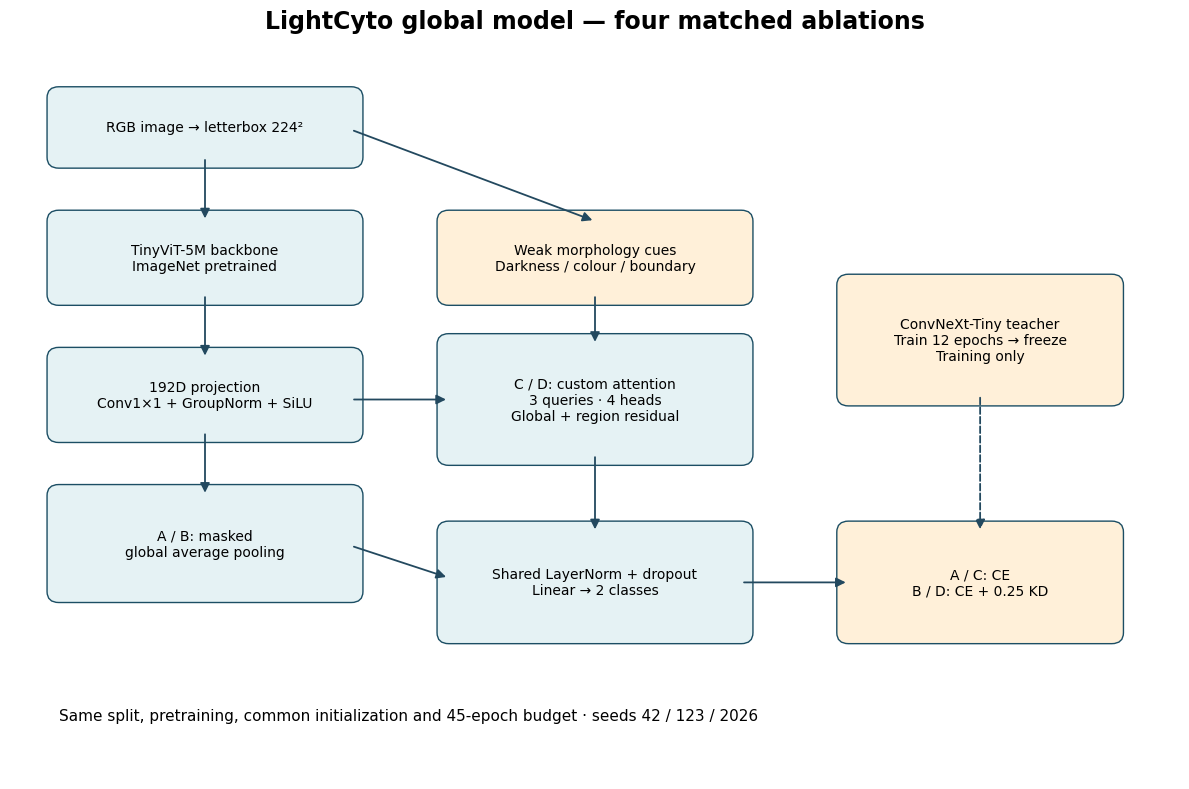

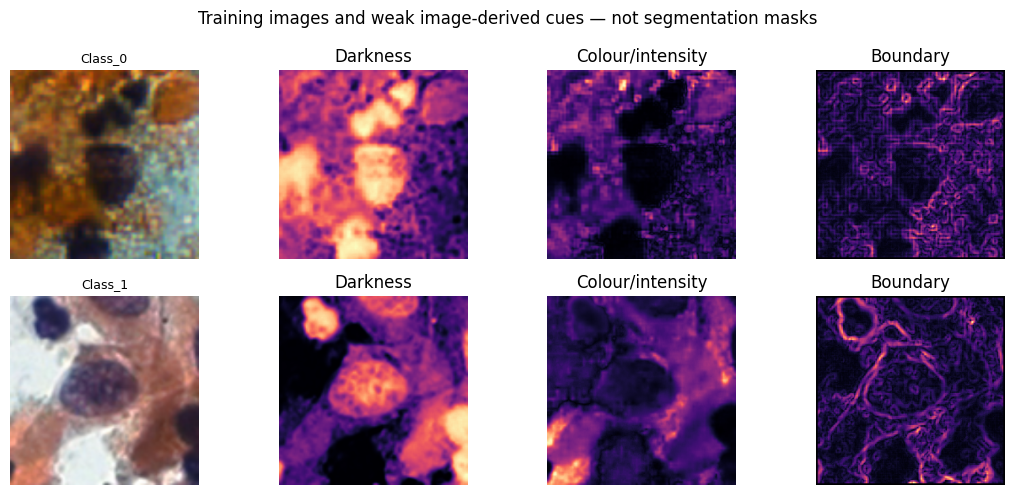

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 244MB/s] 


teacher 1/12: val acc 90.98%, F1 90.68%; 105.5s, stage ETA ~19.4 min
teacher 2/12: val acc 92.35%, F1 91.92%; 81.4s, stage ETA ~13.6 min
teacher 3/12: val acc 91.46%, F1 90.95%; 81.3s, stage ETA ~12.2 min
teacher 4/12: val acc 94.13%, F1 93.92%; 81.2s, stage ETA ~10.8 min
teacher 5/12: val acc 94.37%, F1 94.21%; 80.9s, stage ETA ~9.4 min
teacher 6/12: val acc 95.31%, F1 95.16%; 80.4s, stage ETA ~8.0 min
teacher 7/12: val acc 94.72%, F1 94.50%; 80.4s, stage ETA ~6.7 min
teacher 8/12: val acc 95.14%, F1 94.98%; 80.7s, stage ETA ~5.4 min
teacher 9/12: val acc 95.37%, F1 95.20%; 80.5s, stage ETA ~4.0 min
teacher 10/12: val acc 94.84%, F1 94.65%; 82.4s, stage ETA ~2.7 min
teacher 11/12: val acc 95.37%, F1 95.21%; 80.6s, stage ETA ~1.3 min
teacher 12/12: val acc 95.67%, F1 95.49%; 80.3s, stage ETA ~0.0 min


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.6MB            

model.safetensors: downloading bytes:           |  0.00B            

A_PLAIN/seed_42 1/45: val acc 90.27%, F1 89.94%; 73.0s, stage ETA ~53.5 min
A_PLAIN/seed_42 2/45: val acc 89.21%, F1 89.09%; 61.5s, stage ETA ~44.1 min
A_PLAIN/seed_42 3/45: val acc 92.23%, F1 91.95%; 61.4s, stage ETA ~43.0 min
A_PLAIN/seed_42 4/45: val acc 92.65%, F1 92.50%; 60.0s, stage ETA ~41.0 min
A_PLAIN/seed_42 5/45: val acc 92.41%, F1 91.98%; 60.2s, stage ETA ~40.1 min
A_PLAIN/seed_42 6/45: val acc 91.58%, F1 91.20%; 60.2s, stage ETA ~39.2 min
A_PLAIN/seed_42 7/45: val acc 94.60%, F1 94.38%; 60.4s, stage ETA ~38.3 min
A_PLAIN/seed_42 8/45: val acc 94.48%, F1 94.25%; 60.3s, stage ETA ~37.2 min
A_PLAIN/seed_42 9/45: val acc 94.13%, F1 93.90%; 60.4s, stage ETA ~36.2 min
A_PLAIN/seed_42 10/45: val acc 93.06%, F1 92.69%; 61.1s, stage ETA ~35.7 min
A_PLAIN/seed_42 11/45: val acc 94.25%, F1 94.03%; 62.1s, stage ETA ~35.2 min
A_PLAIN/seed_42 12/45: val acc 94.48%, F1 94.32%; 62.8s, stage ETA ~34.5 min
A_PLAIN/seed_42 13/45: val acc 95.79%, F1 95.64%; 61.1s, stage ETA ~32.6 min
A_PLAIN/

In [15]:
CONTEXT = prepare_ablation()
display(pd.read_csv(CONTEXT['root']/'csv_image_coverage_by_class.csv'))
display(pd.read_csv(CONTEXT['root']/'split_summary.csv'))
fig = architecture_figure()
fig.savefig(CONTEXT['root']/'architecture.png',dpi=150)
fig.savefig(CONTEXT['root']/'architecture.svg')
plt.show();plt.close(fig)
fig = show_training_examples(CONTEXT)
plt.show();plt.close(fig)
STATUS = run_ablation(CONTEXT)
print(json.dumps(STATUS,indent=2))

## Read the results

Metrics use fractions in raw CSVs and percentages in `paper_ablation_table.csv`. Seed SD is in percentage points. See `data_audit.json` for the grouping limitation. Do not compare a binary task’s accuracy directly with a four-class task’s accuracy as if task difficulty were identical.

In [16]:
for filename in ['paper_ablation_table.csv','validation_results_summary.csv',
                 'final_test/test_results_summary.csv','final_test/paired_effects.csv',
                 'efficiency/efficiency_summary.csv']:
    path=CONTEXT['root']/filename
    if path.exists():
        print(filename);display(pd.read_csv(path))
print('Status:',read_json(CONTEXT['root']/'session_status.json'))
print('Reports ZIP:',export_reports(CONTEXT))

validation_results_summary.csv


,arm,seeds,n_unique_images,accuracy_mean,accuracy_seed_sd,macro_f1_mean,macro_f1_seed_sd,balanced_accuracy_mean,aggregation
0,A_PLAIN,3,1686,0.961447,0.002139,0.960089,0.002212,0.958609,Three single-model runs on the same images; no...
1,B_KD,3,1686,0.961843,0.002083,0.960512,0.002111,0.959161,Three single-model runs on the same images; no...
2,C_ATTENTION,3,1686,0.960459,0.002246,0.959186,0.002199,0.958986,Three single-model runs on the same images; no...
3,D_FULL,3,1686,0.963820,0.003138,0.962554,0.003282,0.961201,Three single-model runs on the same images; no...


final_test/test_results_summary.csv


,arm,seeds,n_unique_images,accuracy_mean,accuracy_seed_sd,macro_f1_mean,macro_f1_seed_sd,balanced_accuracy_mean,aggregation
0,A_PLAIN,3,1686,0.955516,0.002966,0.953982,0.003109,0.952663,Three single-model runs on the same images; no...
1,B_KD,3,1686,0.955318,0.000906,0.953773,0.000988,0.952424,Three single-model runs on the same images; no...
2,C_ATTENTION,2,1686,0.956999,0.000419,0.955598,0.000372,0.955064,Three single-model runs on the same images; no...


Status: {'status': 'paused', 'reason': 'Session budget reached; resume this full output.', 'completed_student_jobs': 12, 'planned_student_jobs': 12, 'resume': 'Save the FULL output, attach it, set resume_source, and Run All.'}
Reports ZIP: /kaggle/working/lightcyto_cric_ablation/lightcyto_cric_ablation_reports.zip


## Resume after a Kaggle session ends

1. Save/download the **whole `lightcyto_cric_ablation` folder**, including `.pt` files and initialization. The reports ZIP alone cannot resume.
2. Attach that full saved output to a new session together with the same image dataset.
3. Set `CFG.resume_source` in Configuration to the folder containing `ablation_contract.json`. Keep the same training settings and environment. **Run All.** Completed jobs and matching evaluations are reused; only unfinished training continues.
4. If the notebook reports changed code/data/runtime, restore the compatible environment or use a new output folder. Never bypass identity checks to mix experiments.

Each notebook trains its own teacher. Do not point `resume_source` to a SIPaKMeD run or the other dataset's output. No previous checkpoint attachment is required for a fresh run.

## Sources and interpretation

- [Dataset supplied by you](https://www.kaggle.com/datasets/alexfordna/cric-dataset) — public metadata, file paths and representative image verified while preparing this notebook.
- [TinyViT pretrained model card](https://huggingface.co/timm/tiny_vit_5m_224.dist_in22k_ft_in1k).
- [CRIC original database publication](https://www.nature.com/articles/s41597-021-00933-8) — parent resource; does not establish a crop-to-patient mapping or binary code meaning for the Kaggle repack.

These runs train and evaluate this method separately on each dataset. Report the input unit, labels, split, grouping provenance, sample counts, three-seed variability and CI resampling unit. They are not prospective clinical validation. GPU training has **not** been run for you in this file; outputs will appear when you run the notebook.